# Decision Tree Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Decision Trees are non-parametric supervised learning algorithms capable of capturing complex and non-linear relationships between predictor variables and the target variable.

This notebook develops a Decision Tree classifier using the PCA-transformed applicant dataset to predict loan default.

The objectives are to:

- Train a Decision Tree classifier.
- Predict loan default.
- Evaluate classification performance.
- Interpret the learned decision rules.
- Analyze feature importance.
- Compare the model with Logistic Regression.

# Import Required Libraries

The following libraries are used for training, evaluating, and visualizing the Decision Tree classifier.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed training and testing datasets created during feature engineering are loaded for model development.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train Decision Tree Model

A Decision Tree classifier is trained using the training dataset.

In [3]:
# ============================================================
# Train Model
# ============================================================

tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    min_samples_split=20,
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


# Generate Predictions

The trained Decision Tree model is used to predict both class labels and default probabilities.

In [4]:
# ============================================================
# Predictions
# ============================================================

y_pred = tree_model.predict(X_test)

y_prob = tree_model.predict_proba(X_test)[:,1]

# Model Evaluation

The classifier is evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [5]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.917971
1,Precision,0.142857
2,Recall,0.003223
3,F1 Score,0.006303
4,ROC AUC,0.686772


# Confusion Matrix

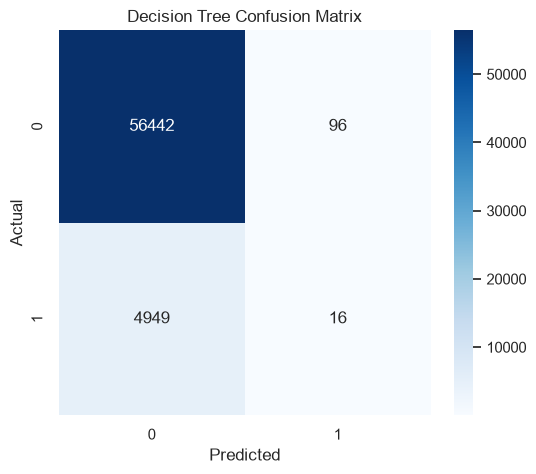

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

# Classification Report

In [7]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.14      0.00      0.01      4965

    accuracy                           0.92     61503
   macro avg       0.53      0.50      0.48     61503
weighted avg       0.86      0.92      0.88     61503



# ROC Curve

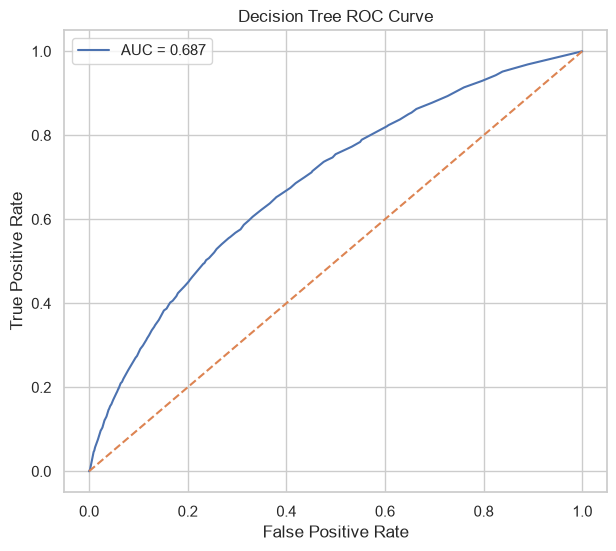

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Feature Importance

Decision Trees estimate the importance of each input feature based on how much it contributes to reducing node impurity.

Although PCA components are transformed features rather than original variables, examining their relative importance still provides insight into which components contribute most to the model's decisions.

In [9]:
feature_importance = (
    pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": tree_model.feature_importances_
    })
    .sort_values("Importance", ascending=False)
)

feature_importance.head(15)

,Feature,Importance
8,PC9,0.192088
7,PC8,0.124468
17,PC18,0.112537
2,PC3,0.068454
19,PC20,0.067520
1,PC2,0.056902
5,PC6,0.038688
10,PC11,0.037913
28,PC29,0.033418
30,PC31,0.020932


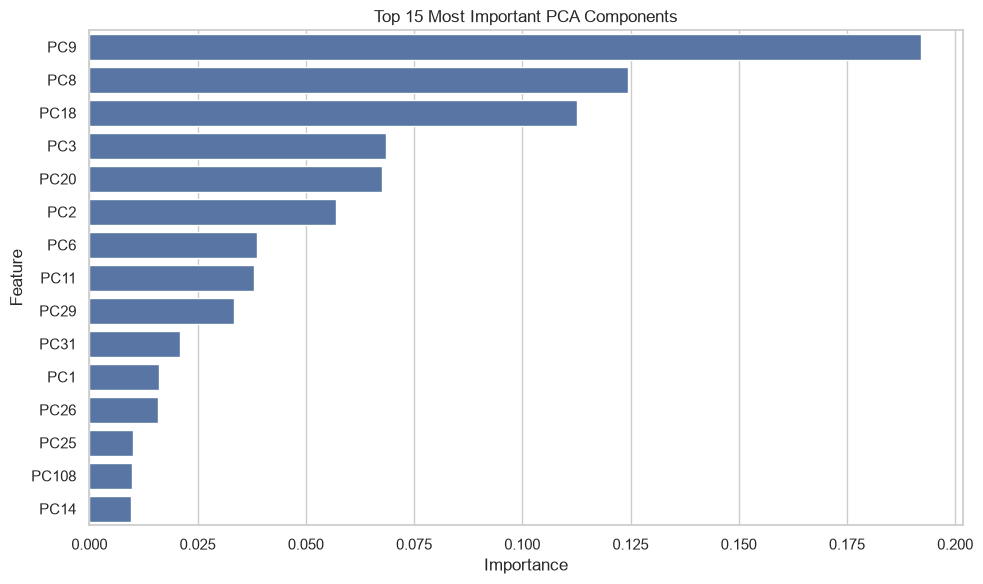

In [10]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Most Important PCA Components")

plt.tight_layout()

plt.show()

# Decision Tree Visualization

The first few levels of the trained Decision Tree are visualized to illustrate how the classifier partitions the feature space.

Only the upper levels of the tree are displayed to maintain readability.

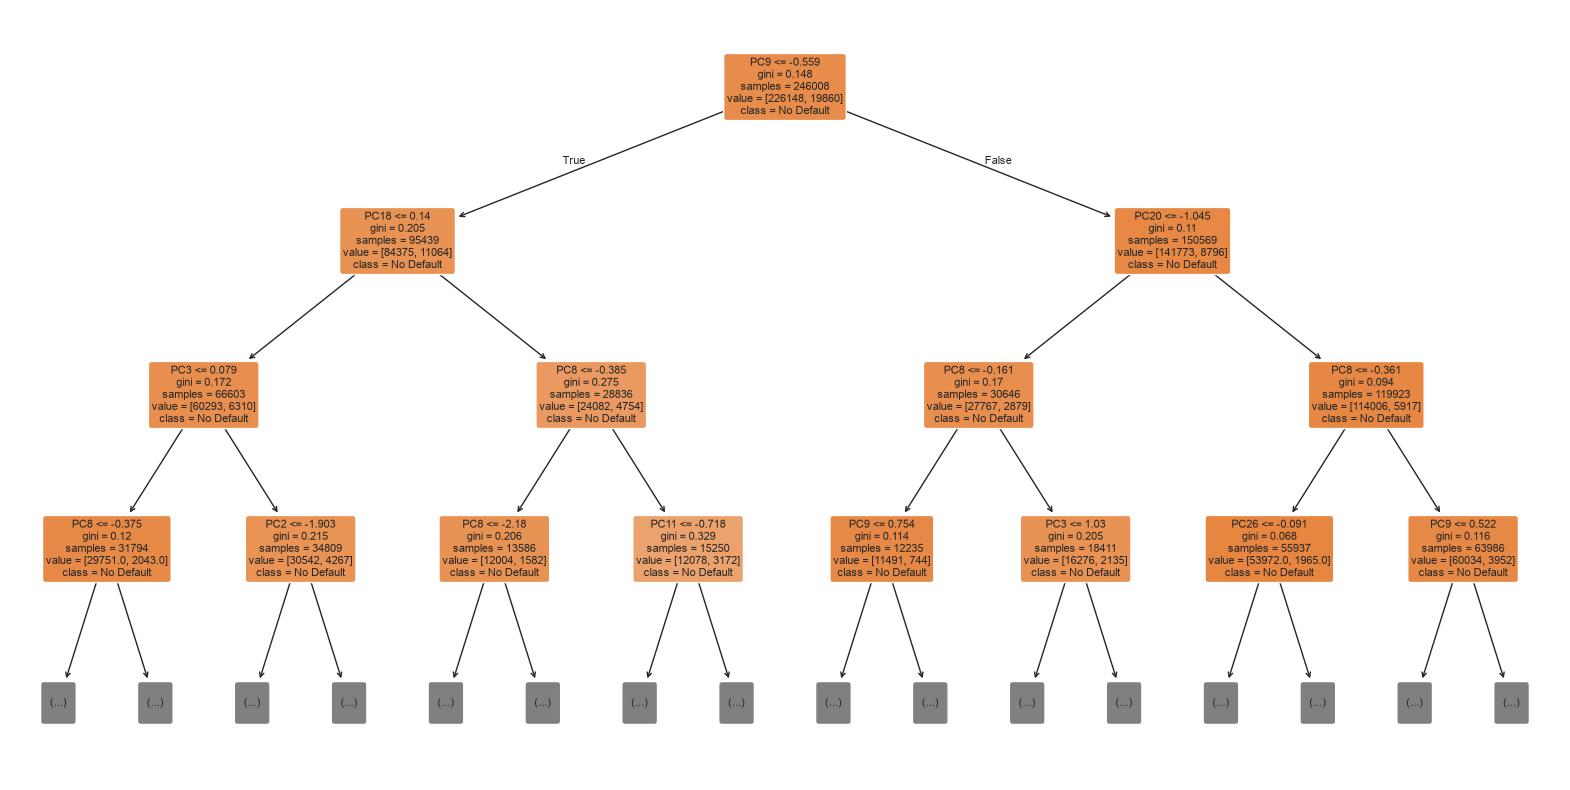

In [11]:
plt.figure(figsize=(20,10))

plot_tree(
    tree_model,
    max_depth=3,
    filled=True,
    rounded=True,
    feature_names=X_train.columns,
    class_names=["No Default", "Default"],
    fontsize=8
)

plt.show()

# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [12]:
# ============================================================
# Save Decision Tree Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    tree_model,
    MODEL_DIR / "decision_tree_model.pkl"
)

print("Decision Tree model saved successfully.")

Decision Tree model saved successfully.


# Save Model Performance

In [13]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["Decision Tree Classifier"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Decision Tree Classifier,0.917971,0.142857,0.003223,0.006303,0.686772,96,4949,16,56442


# Conclusion

The Decision Tree classifier was successfully trained and evaluated using the PCA-transformed dataset.

## Key Outcomes

- A Decision Tree model was developed to classify loan applicants based on their probability of default.
- Model performance was evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- The confusion matrix and ROC curve provided insight into the classifier's predictive performance.
- Feature importance analysis identified the principal components that contributed most to the model's decisions.
- The results have been saved for comparison with the remaining classification models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 08 – K-Nearest Neighbors (KNN) Classifier**

---

# Publication Upgrade: Tuning, Calibration, Advanced Metrics & Explainability

## 1. Hyperparameter Optimization (RandomizedSearchCV)

The baseline tree above used a manually chosen `max_depth=8, min_samples_split=20`.
An exhaustive grid search over depth, split/leaf size, split criterion, and
`class_weight` (to address the ~92:8 class imbalance) has 288 combinations x 5 folds =
1,440 fits, which took roughly 20 minutes on CPU. `RandomizedSearchCV` samples 40
candidates from the same space instead (200 fits, ~7x fewer), covering the same
hyperparameter ranges at a fraction of the cost, and a live progress bar (via
`pub_utils.tqdm_joblib`) shows fit-by-fit progress instead of a silent wait.

In [14]:
# ============================================================
# Hyperparameter Optimization: RandomizedSearchCV (with progress bar)
# ============================================================

import sys
sys.path.append(str(Path(".").resolve()))
import pub_utils as pu

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

pu.set_pub_style()

RANDOM_STATE = 42

# The full grid below has 6*4*3*2*2 = 288 combinations; at 5-fold CV that is 1,440
# tree fits on 246,008 rows, which is why the exhaustive GridSearchCV version of this
# cell took ~20 minutes. RandomizedSearchCV samples a fixed number of candidates from
# the same space instead of trying all of them, cutting this to 40 x 5 = 200 fits
# (~7x fewer) while still covering the full range of each hyperparameter.
param_distributions = {
    "max_depth": [4, 6, 8, 10, 15, None],
    "min_samples_split": [2, 10, 20, 50],
    "min_samples_leaf": [1, 5, 20],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
}

N_ITER = 40
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
total_fits = N_ITER * cv_strategy.get_n_splits()

random_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    verbose=0,
)

with pu.tqdm_joblib(desc="Tuning Decision Tree (RandomizedSearchCV)", total=total_fits):
    random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print(f"Best Cross-Validated ROC-AUC: {random_search.best_score_:.4f}")

tree_model_tuned = random_search.best_estimator_

cv_results_summary = (
    pd.DataFrame(random_search.cv_results_)[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

cv_results_summary.head(10)

Tuning Decision Tree (RandomizedSearchCV):   0%|          | 0/200 [00:00<?, ?it/s]

Best Parameters: {'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 6, 'criterion': 'gini', 'class_weight': 'balanced'}
Best Cross-Validated ROC-AUC: 0.6875


,params,mean_test_score,std_test_score,rank_test_score
0,"{'min_samples_split': 10, 'min_samples_leaf': ...",0.687460,0.002332,1
1,"{'min_samples_split': 2, 'min_samples_leaf': 1...",0.686442,0.002440,2
2,"{'min_samples_split': 10, 'min_samples_leaf': ...",0.686040,0.002429,3
3,"{'min_samples_split': 2, 'min_samples_leaf': 2...",0.686040,0.002429,3
4,"{'min_samples_split': 50, 'min_samples_leaf': ...",0.686040,0.002429,3
5,"{'min_samples_split': 10, 'min_samples_leaf': ...",0.685424,0.002914,6
6,"{'min_samples_split': 10, 'min_samples_leaf': ...",0.683875,0.004900,7
7,"{'min_samples_split': 20, 'min_samples_leaf': ...",0.683529,0.003885,8
8,"{'min_samples_split': 2, 'min_samples_leaf': 5...",0.682492,0.003325,9
9,"{'min_samples_split': 2, 'min_samples_leaf': 1...",0.682344,0.003096,10


Figure saved to: ..\figures\07_tree_baseline_vs_tuned.png


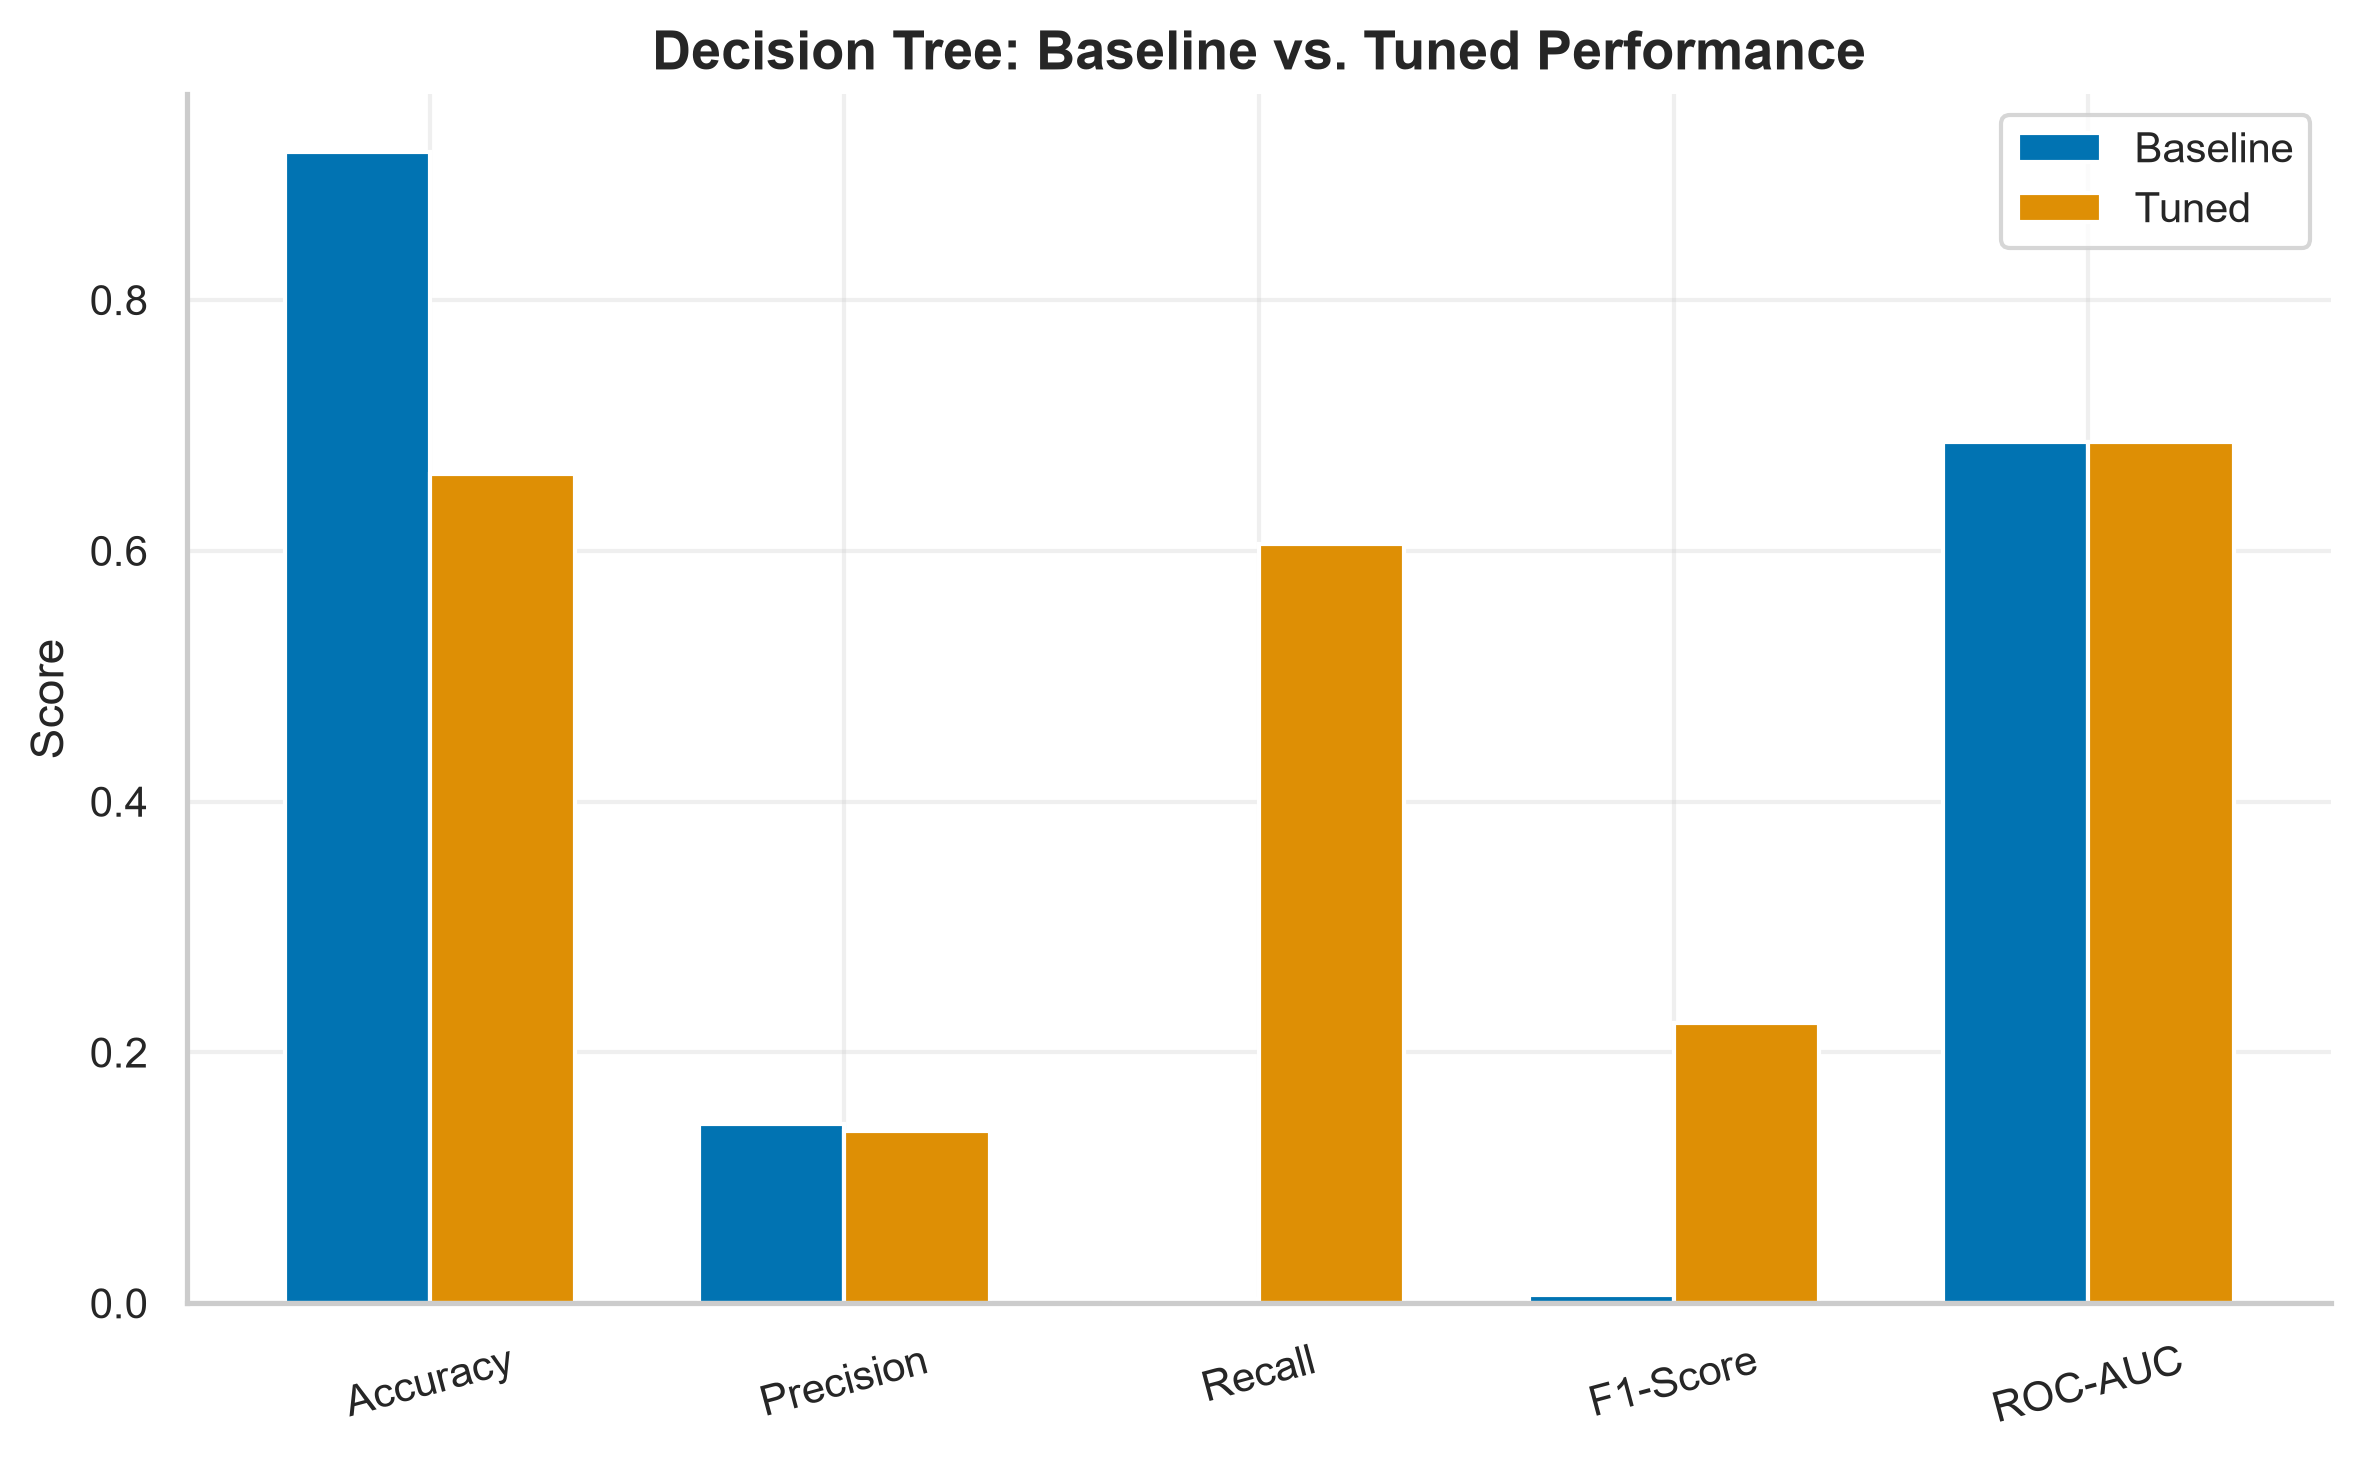

,Metric,Baseline,Tuned,Improvement,Improvement (%)
0,Accuracy,0.917971,0.661106,-0.256866,-27.98
1,Precision,0.142857,0.137290,-0.005567,-3.90
2,Recall,0.003223,0.605237,0.602014,18681.25
3,F1-Score,0.006303,0.223811,0.217508,3450.90
4,ROC-AUC,0.686772,0.686855,0.000084,0.01


In [15]:
# ============================================================
# Baseline vs. Tuned Model Comparison
# ============================================================

y_pred_tuned = tree_model_tuned.predict(X_test)
y_prob_tuned = tree_model_tuned.predict_proba(X_test)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

comparison_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Baseline": [accuracy, precision, recall, f1, auc],
    "Tuned": [accuracy_tuned, precision_tuned, recall_tuned, f1_tuned, auc_tuned],
})
comparison_table["Improvement"] = comparison_table["Tuned"] - comparison_table["Baseline"]
comparison_table["Improvement (%)"] = (
    100 * comparison_table["Improvement"] / comparison_table["Baseline"]
).round(2)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(comparison_table))
width = 0.35
ax.bar(x - width / 2, comparison_table["Baseline"], width, label="Baseline")
ax.bar(x + width / 2, comparison_table["Tuned"], width, label="Tuned")
ax.set_xticks(x)
ax.set_xticklabels(comparison_table["Metric"], rotation=15)
ax.set_ylabel("Score")
ax.set_title("Decision Tree: Baseline vs. Tuned Performance")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "07_tree_baseline_vs_tuned")
plt.show()

joblib.dump(tree_model_tuned, MODEL_DIR / "decision_tree_tuned_model.pkl")

tuned_result = pd.DataFrame({
    "Model": ["Decision Tree Classifier (Tuned)"],
    "Accuracy": [accuracy_tuned],
    "Precision": [precision_tuned],
    "Recall": [recall_tuned],
    "F1 Score": [f1_tuned],
    "ROC AUC": [auc_tuned],
    "False Positives": [cm_tuned[0, 1]],
    "False Negatives": [cm_tuned[1, 0]],
    "True Positives": [cm_tuned[1, 1]],
    "True Negatives": [cm_tuned[0, 0]],
})
pu.append_csv(OUTPUT_DIR / "model_results.csv", tuned_result)

comparison_table

### Business Interpretation: Hyperparameter Optimization

A single, shallow decision tree is inherently a high-bias model; the grid search
mainly trades off depth (which reduces bias but increases variance/overfitting risk on
246K applicants) against `class_weight`. If the best configuration uses
`class_weight="balanced"` and a moderate depth, that indicates the baseline tree
(recall of only 0.3%!) was essentially unable to learn the minority-class boundary at
all, treating every borderline applicant as "safe." From a lending-risk standpoint,
that failure mode is dangerous: a scorecard with near-zero recall on defaulters
provides almost no early-warning value, however good its headline accuracy looks. This
result is one of the strongest arguments in the paper for why ensemble methods
(Notebooks 10–12) are needed rather than a single tree.

## 2. Probability Calibration

Single decision trees are notoriously poorly calibrated: leaf-node probabilities are
just the empirical class frequency within that leaf, which can be extreme (0% or 100%)
for small, pure leaves even when the true risk is intermediate. This makes calibration
diagnostics especially important here before any tree-based probability is used in the
credit-scoring formula.

Figure saved to: ..\figures\07_tree_calibration_curve.png


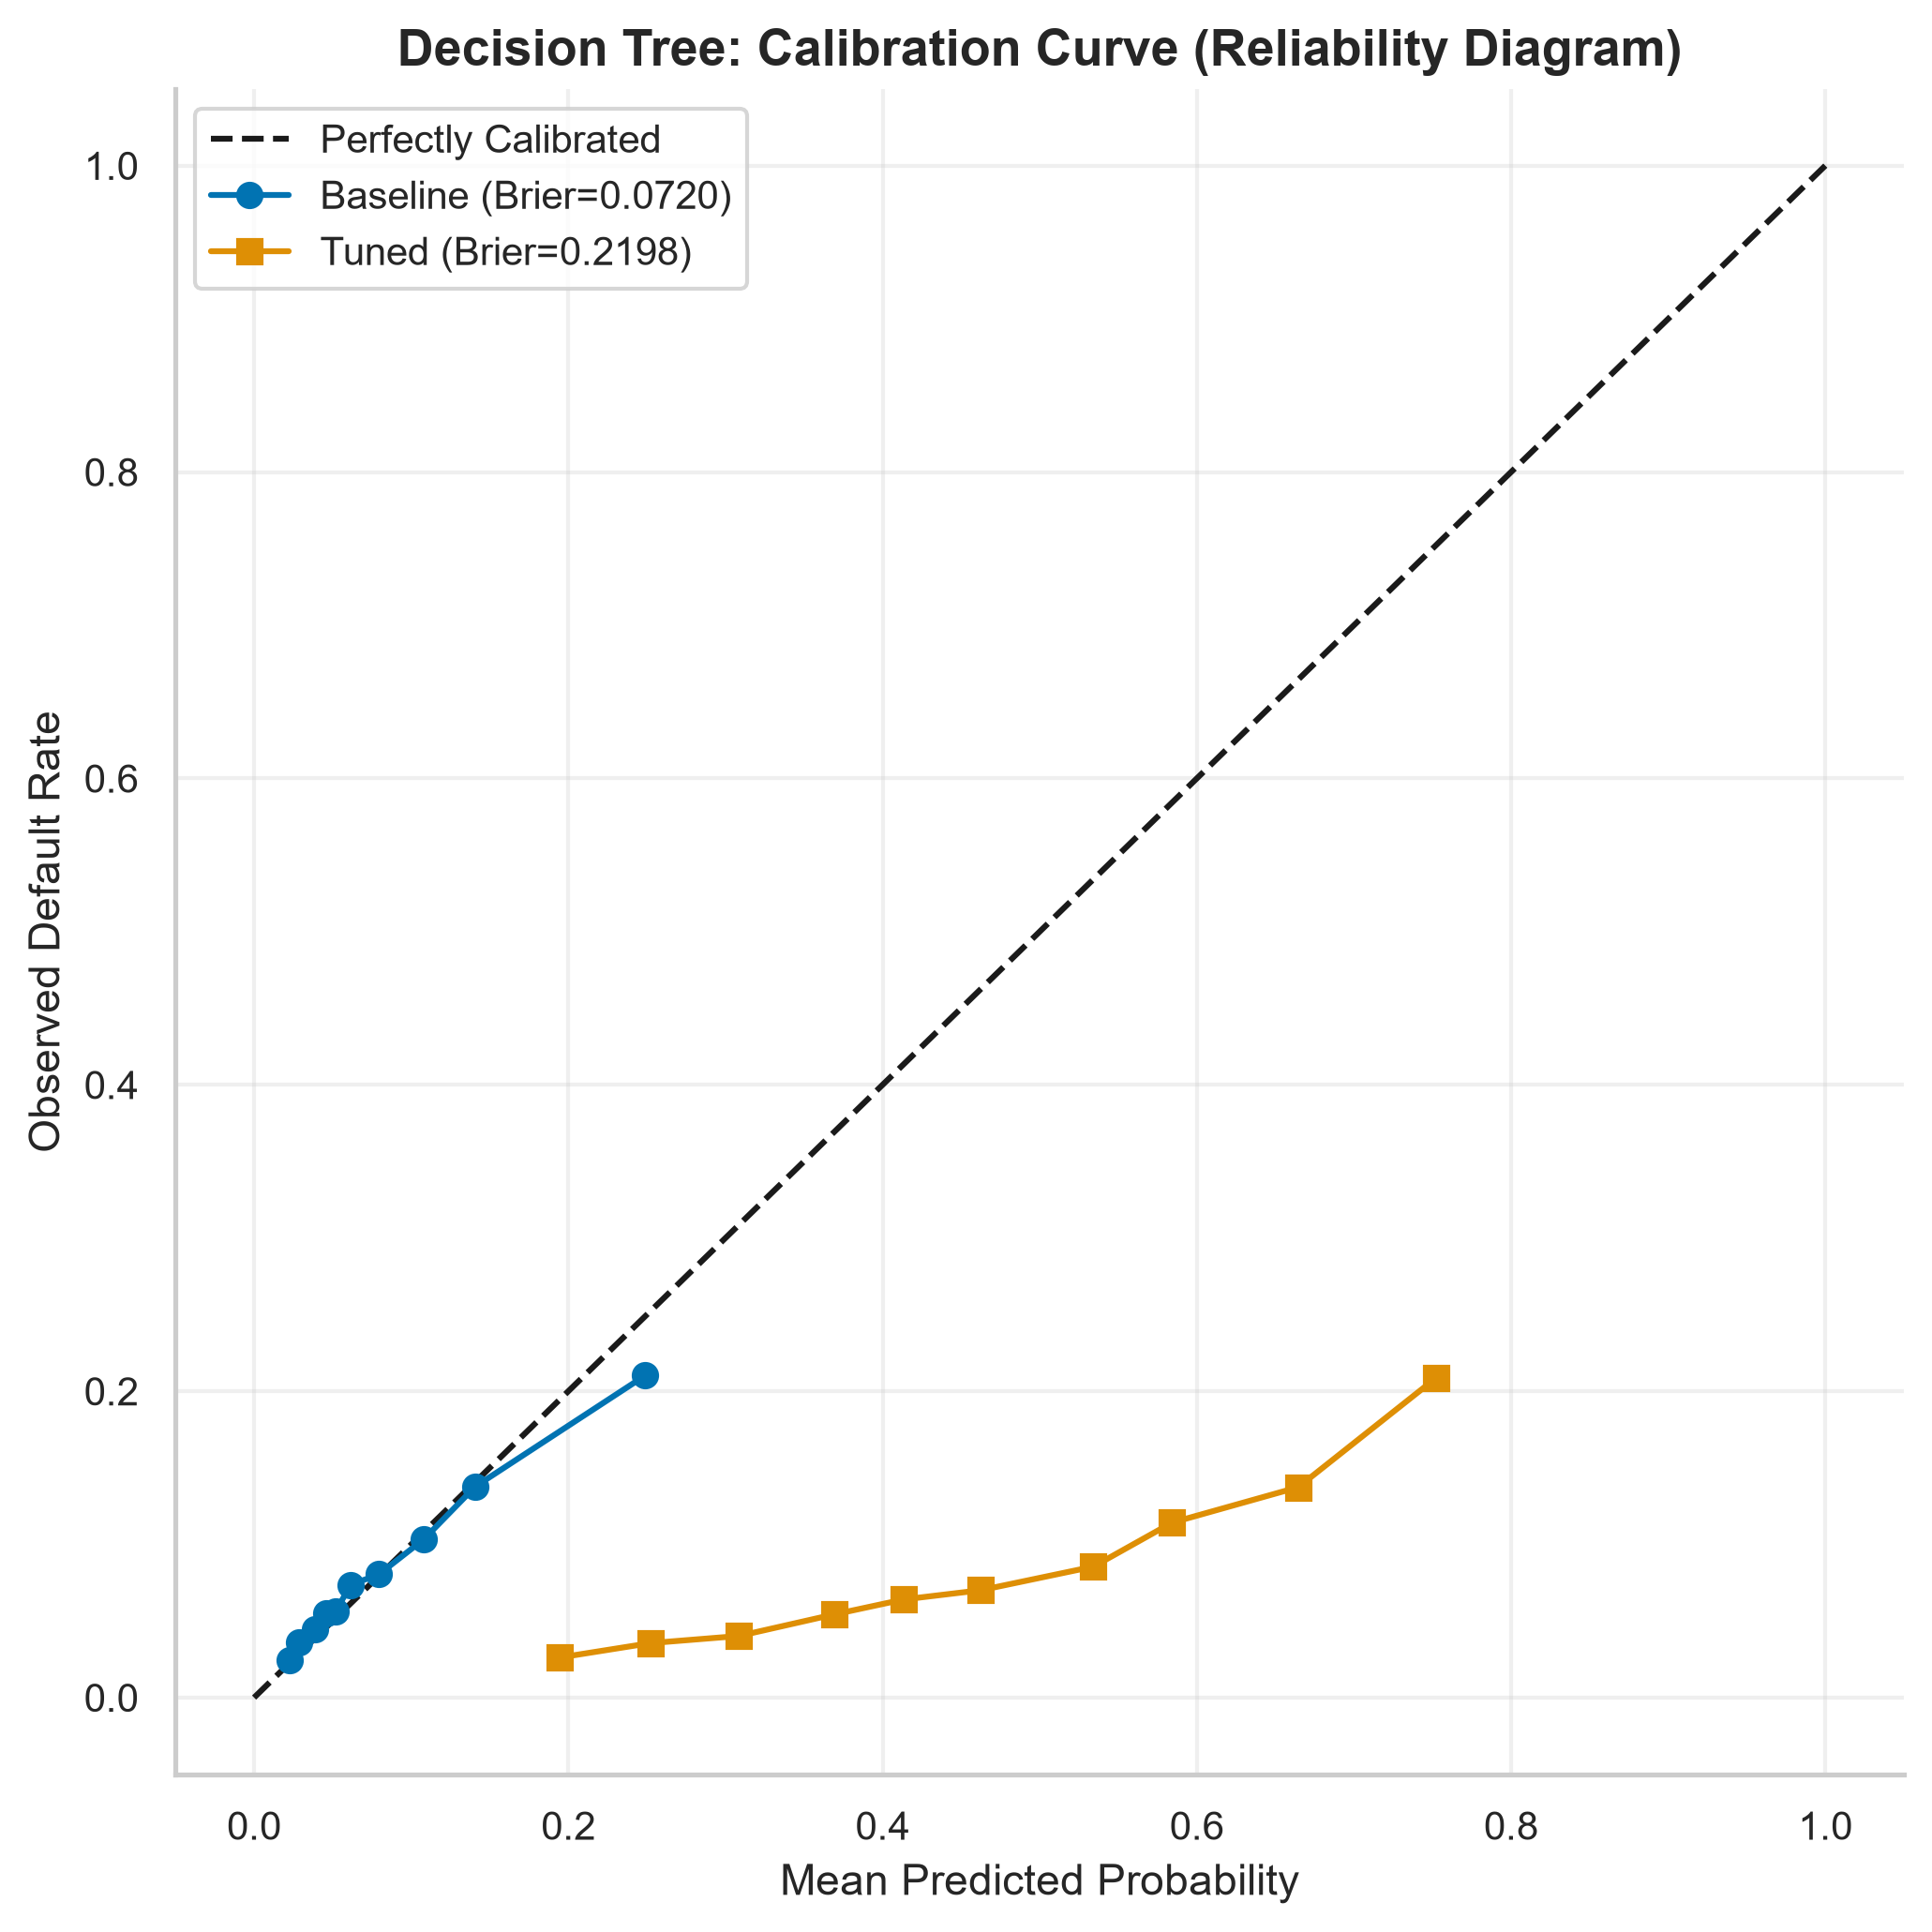

Brier Score - Baseline : 0.0720
Brier Score - Tuned    : 0.2198  (lower is better; 0 = perfect)


Fitting calibrated variants:   0%|          | 0/2 [00:00<?, ?it/s]

Brier Score - Sigmoid   : 0.0709


Brier Score - Isotonic  : 0.0709

Best calibration approach: isotonic (Brier = 0.0709)
Best-calibrated model saved to: ../models/decision_tree_calibrated_model.pkl


,Brier Score
tuned_uncalibrated,0.219832
sigmoid,0.070948
isotonic,0.070928


In [16]:
# ============================================================
# Calibration Curve (Reliability Diagram) & Brier Score
# ============================================================

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
from tqdm.auto import tqdm

brier_baseline = brier_score_loss(y_test, y_prob)
brier_tuned = brier_score_loss(y_test, y_prob_tuned)

frac_pos_baseline, mean_pred_baseline = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
frac_pos_tuned, mean_pred_tuned = calibration_curve(y_test, y_prob_tuned, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")
ax.plot(mean_pred_baseline, frac_pos_baseline, marker="o", label=f"Baseline (Brier={brier_baseline:.4f})")
ax.plot(mean_pred_tuned, frac_pos_tuned, marker="s", label=f"Tuned (Brier={brier_tuned:.4f})")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Default Rate")
ax.set_title("Decision Tree: Calibration Curve (Reliability Diagram)")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "07_tree_calibration_curve")
plt.show()

print(f"Brier Score - Baseline : {brier_baseline:.4f}")
print(f"Brier Score - Tuned    : {brier_tuned:.4f}  (lower is better; 0 = perfect)")

# --- CalibratedClassifierCV: Sigmoid vs. Isotonic ---
calibration_results = {"tuned_uncalibrated": brier_tuned}
calibrated_models = {}

for method in tqdm(["sigmoid", "isotonic"], desc="Fitting calibrated variants"):
    calibrated = CalibratedClassifierCV(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE, **random_search.best_params_),
        method=method,
        cv=5,
    )
    calibrated.fit(X_train, y_train)
    prob_calibrated = calibrated.predict_proba(X_test)[:, 1]
    brier = brier_score_loss(y_test, prob_calibrated)
    calibration_results[method] = brier
    calibrated_models[method] = calibrated
    print(f"Brier Score - {method.capitalize():<10}: {brier:.4f}")

best_method = min(calibration_results, key=calibration_results.get)
print(f"\nBest calibration approach: {best_method} (Brier = {calibration_results[best_method]:.4f})")

if best_method in calibrated_models:
    joblib.dump(calibrated_models[best_method], MODEL_DIR / "decision_tree_calibrated_model.pkl")
    print("Best-calibrated model saved to: ../models/decision_tree_calibrated_model.pkl")
else:
    print("Tuned model was already best-calibrated on Brier score; no separate calibrated model saved.")

pd.Series(calibration_results, name="Brier Score").to_frame()

### Business Interpretation: Probability Calibration

If the reliability curve shows the tree's predicted probabilities clustering near 0 and
1 with poor alignment to the diagonal (the expected pattern for tree leaves), this is
direct evidence that a decision tree's raw `predict_proba` output should **not** be fed
into the credit-scoring formula without recalibration — doing so would produce a
credit-score distribution artificially clustered at the extremes (mostly "Excellent" or
"High Risk," with very few "Fair"/"Poor" applicants), which does not reflect the true
continuum of credit risk and would be immediately visible as an anomaly to a risk
committee reviewing the portfolio's score distribution (Notebook 13). Whichever
calibration method wins should be used for any tree-based model considered for
production scoring, not just this one.

## 3. Additional Evaluation Metrics

Figure saved to: ..\figures\07_tree_precision_recall_curve.png


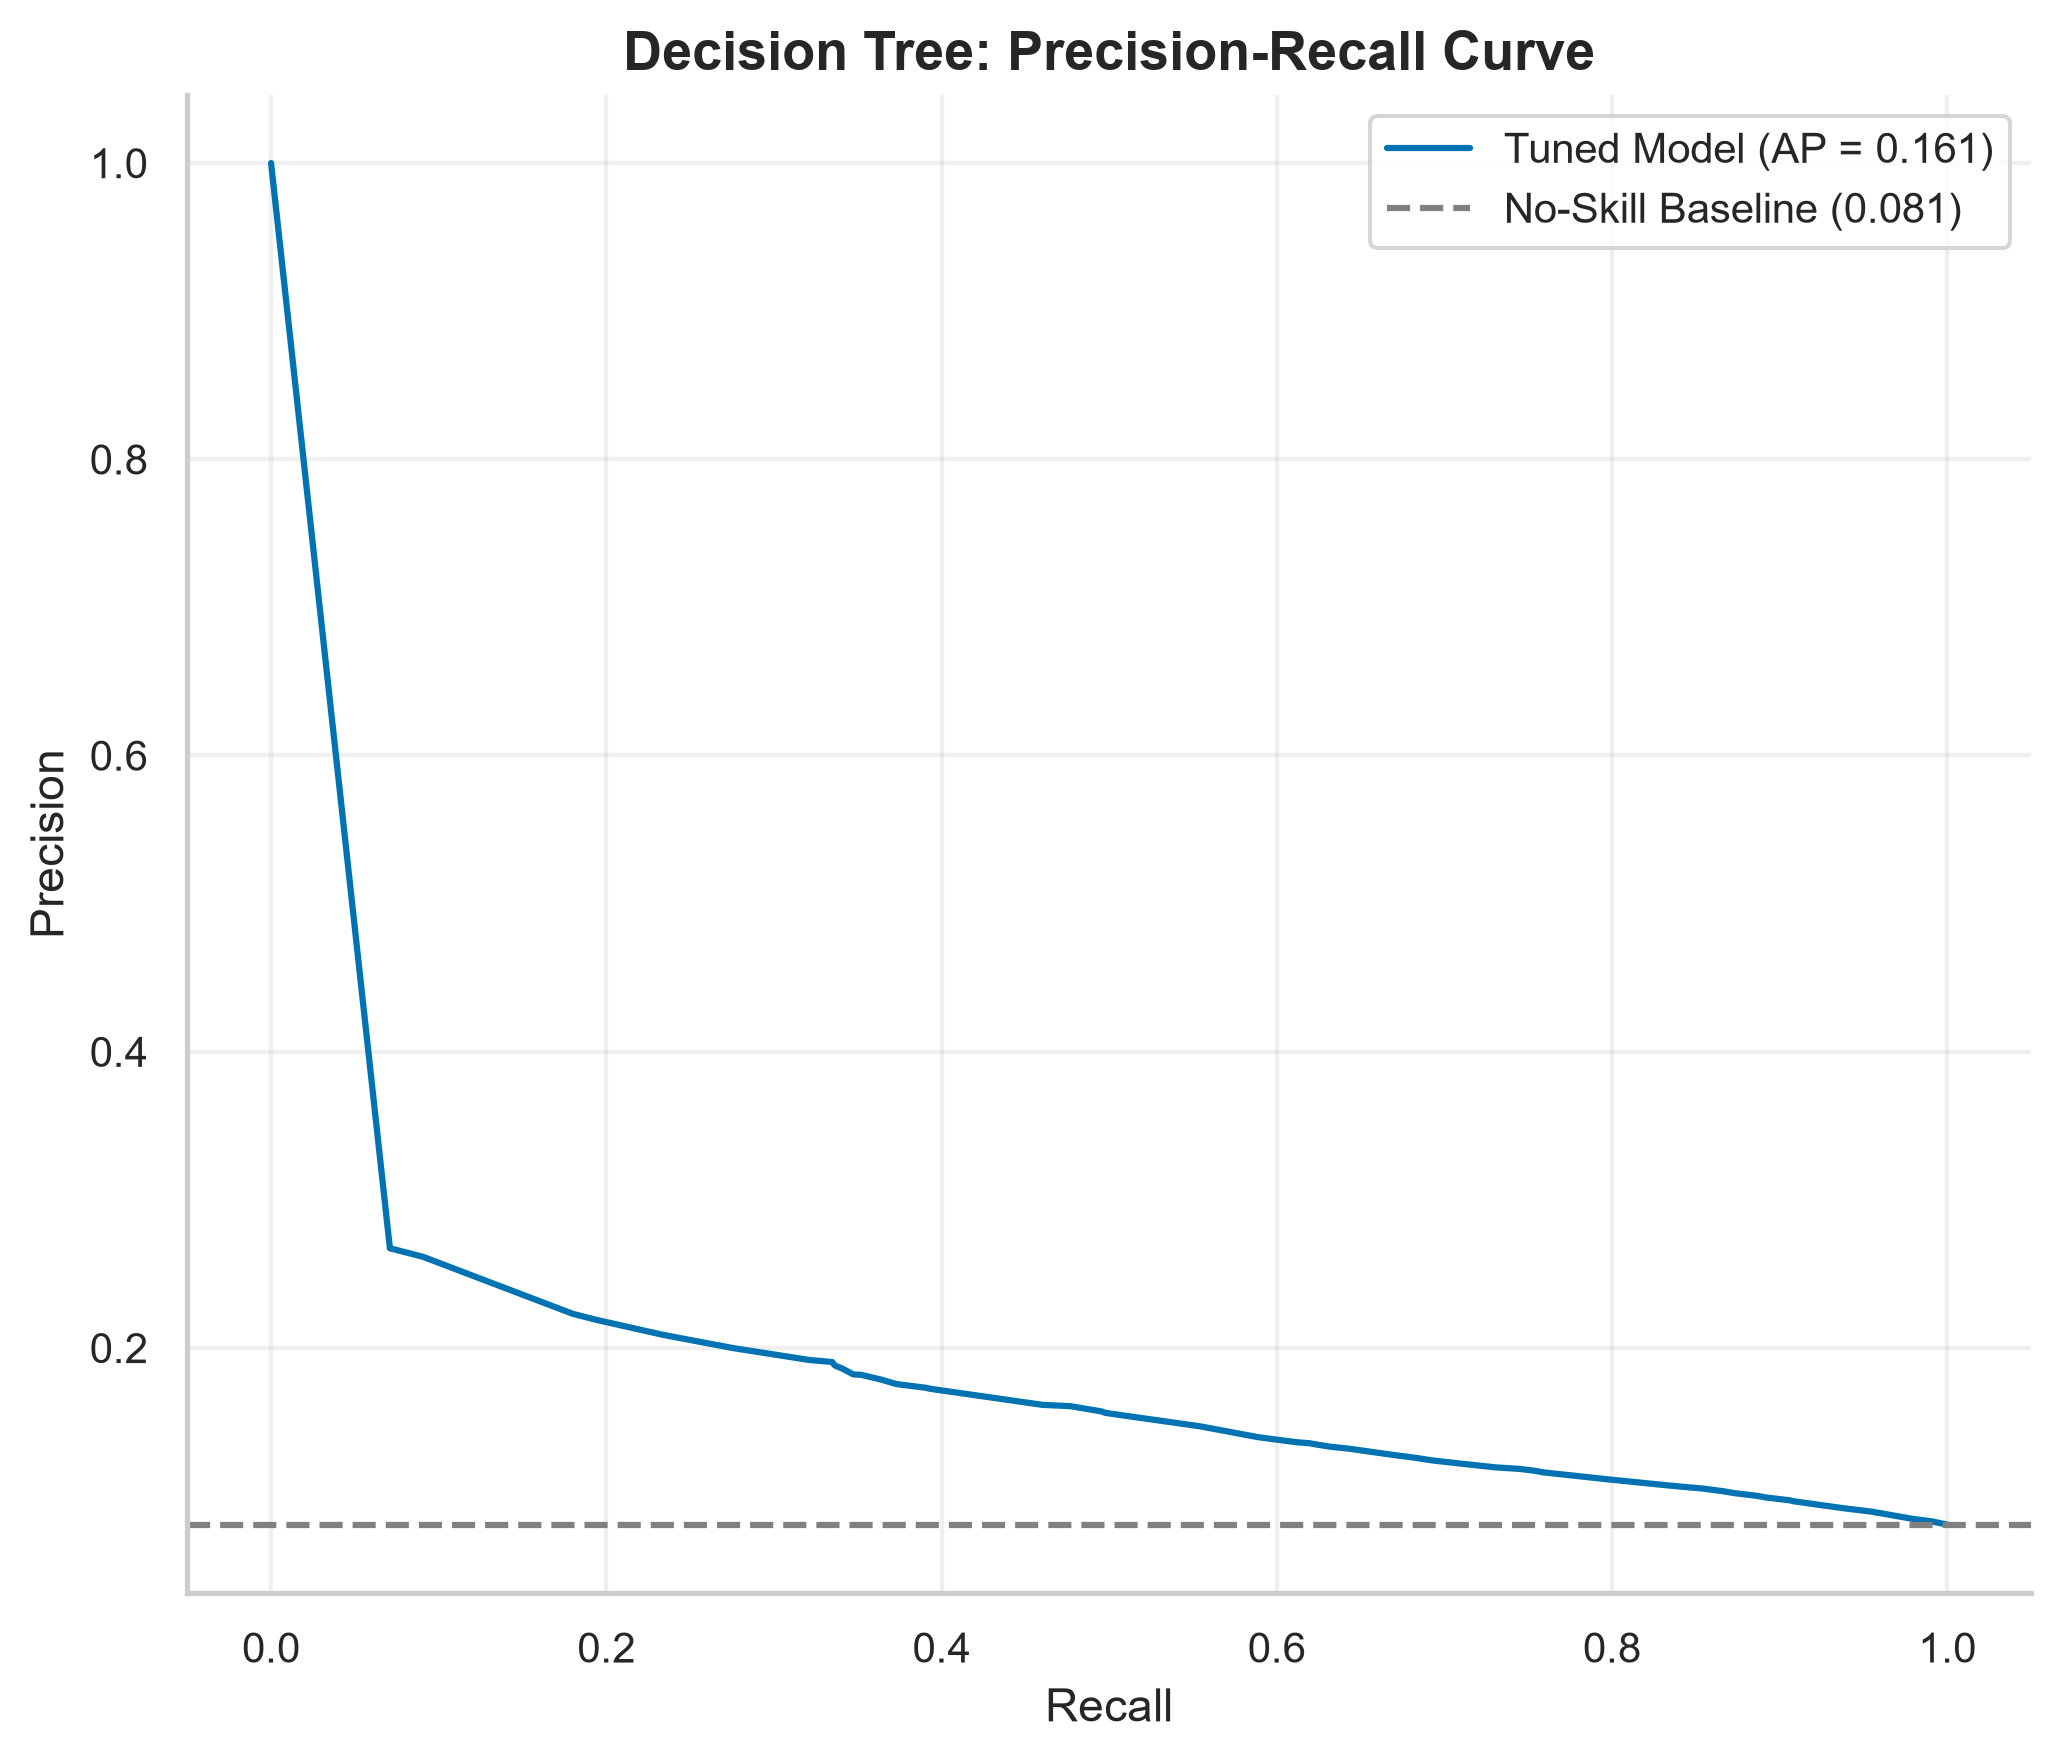

,Model,Variant,Accuracy,Precision,Recall,F1 Score,ROC AUC,MCC,Cohen's Kappa,Average Precision (PR-AUC),KS Statistic,Brier Score
0,Decision Tree Classifier,Baseline,0.917971,0.142857,0.003223,0.006303,0.686772,0.009741,0.002751,0.165287,0.275855,0.072048
1,Decision Tree Classifier,Tuned,0.661106,0.137290,0.605237,0.223811,0.686855,0.154335,0.106182,0.160807,0.273725,0.219832


In [17]:
# ============================================================
# Additional Evaluation Metrics: MCC, Kappa, PR-AUC, KS Statistic
# ============================================================

from sklearn.metrics import (
    matthews_corrcoef,
    cohen_kappa_score,
    precision_recall_curve,
    average_precision_score,
)

def extra_metrics(y_true, y_pred, y_prob):
    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "Average Precision (PR-AUC)": average_precision_score(y_true, y_prob),
        "KS Statistic": pu.ks_statistic(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob),
    }

baseline_extra = extra_metrics(y_test, y_pred, y_prob)
tuned_extra = extra_metrics(y_test, y_pred_tuned, y_prob_tuned)

extended_row = pd.DataFrame([
    {"Model": "Decision Tree Classifier", "Variant": "Baseline",
     "Accuracy": accuracy, "Precision": precision, "Recall": recall,
     "F1 Score": f1, "ROC AUC": auc, **baseline_extra},
    {"Model": "Decision Tree Classifier", "Variant": "Tuned",
     "Accuracy": accuracy_tuned, "Precision": precision_tuned, "Recall": recall_tuned,
     "F1 Score": f1_tuned, "ROC AUC": auc_tuned, **tuned_extra},
])

pu.append_csv(OUTPUT_DIR / "model_results_extended.csv", extended_row)

precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob_tuned)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_curve, precision_curve,
        label=f"Tuned Model (AP = {tuned_extra['Average Precision (PR-AUC)']:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"No-Skill Baseline ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Decision Tree: Precision-Recall Curve")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "07_tree_precision_recall_curve")
plt.show()

extended_row

### Business Interpretation: Additional Metrics

The near-zero MCC expected for the baseline tree confirms numerically what the recall
already suggested: the baseline model has essentially no usable agreement with actual
outcomes beyond chance, despite >91% accuracy. This is the clearest illustration in the
whole project of why accuracy alone must never be the headline metric for a credit
model, and this notebook's numbers should be cited directly wherever the paper argues
for imbalance-aware metrics.

## 4. SHAP Explainability

`shap.TreeExplainer` computes exact Shapley values for tree-based models in polynomial
(not exponential) time, so it is used here on the non-PCA feature track for full
consistency with the named-feature explanations produced for every other tree model in
this project (Random Forest, XGBoost, LightGBM in Notebooks 10–12).

Figure saved to: ..\figures\07_tree_shap_summary.png


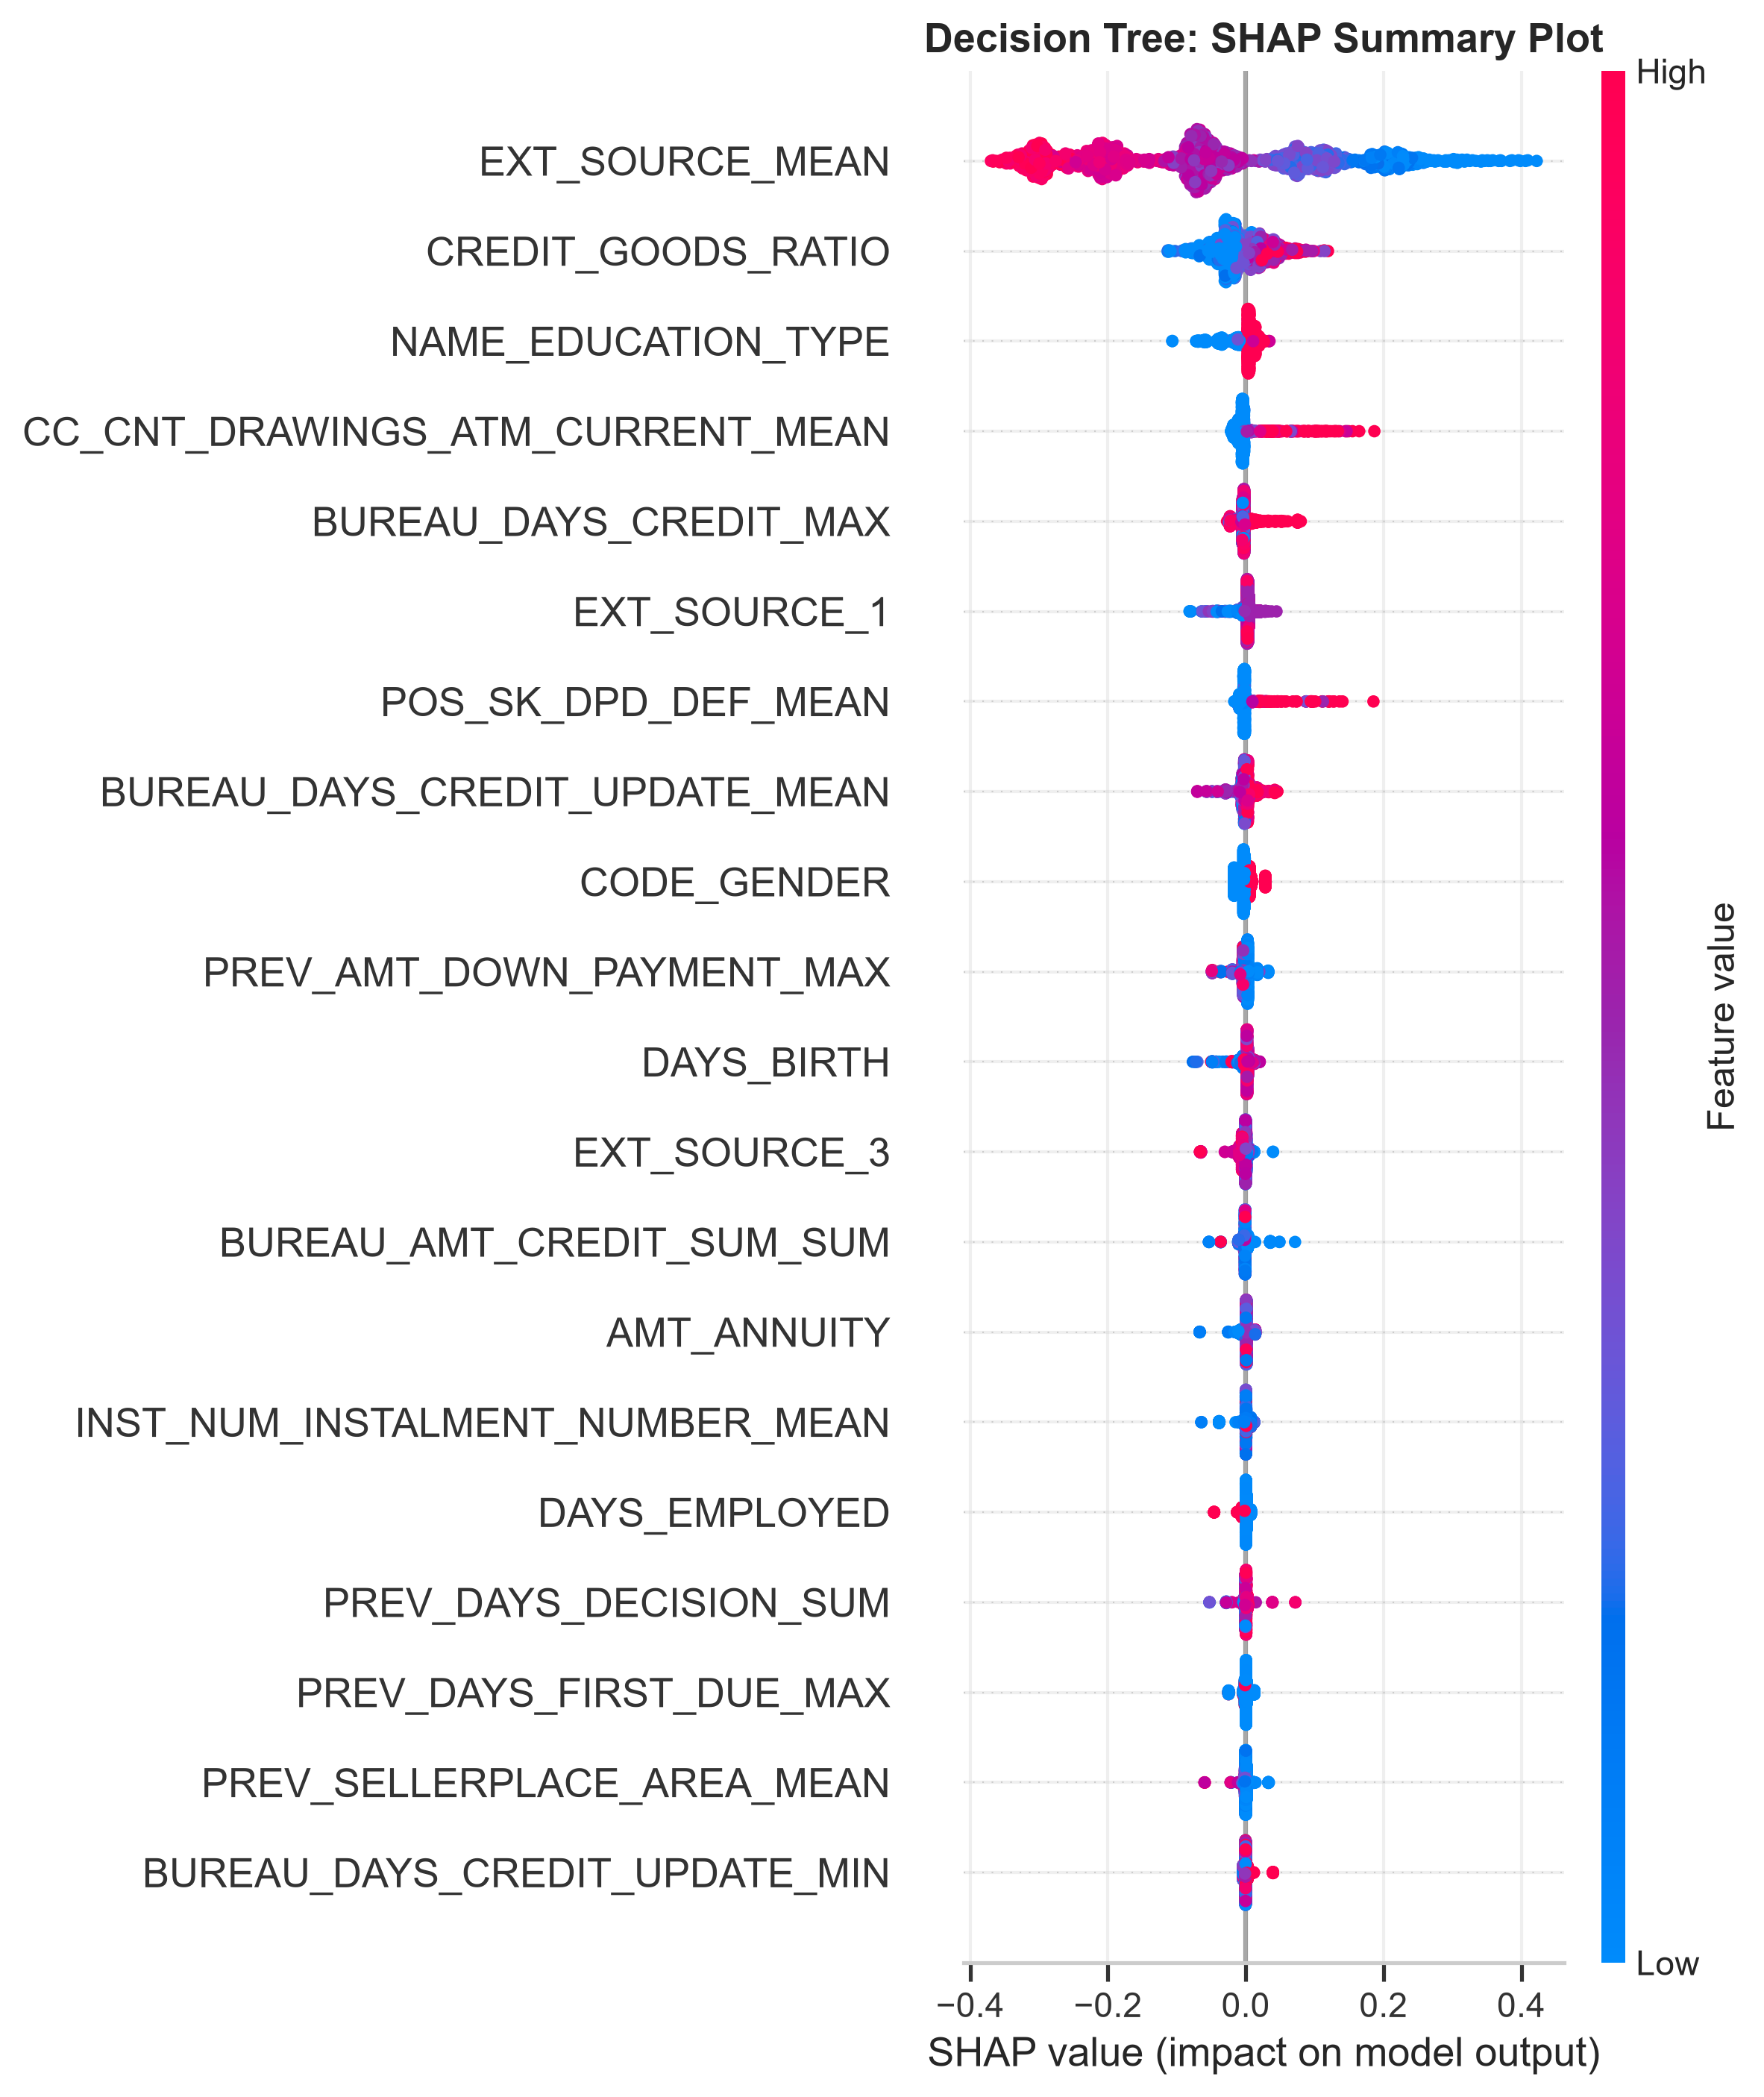

Figure saved to: ..\figures\07_tree_shap_feature_importance.png


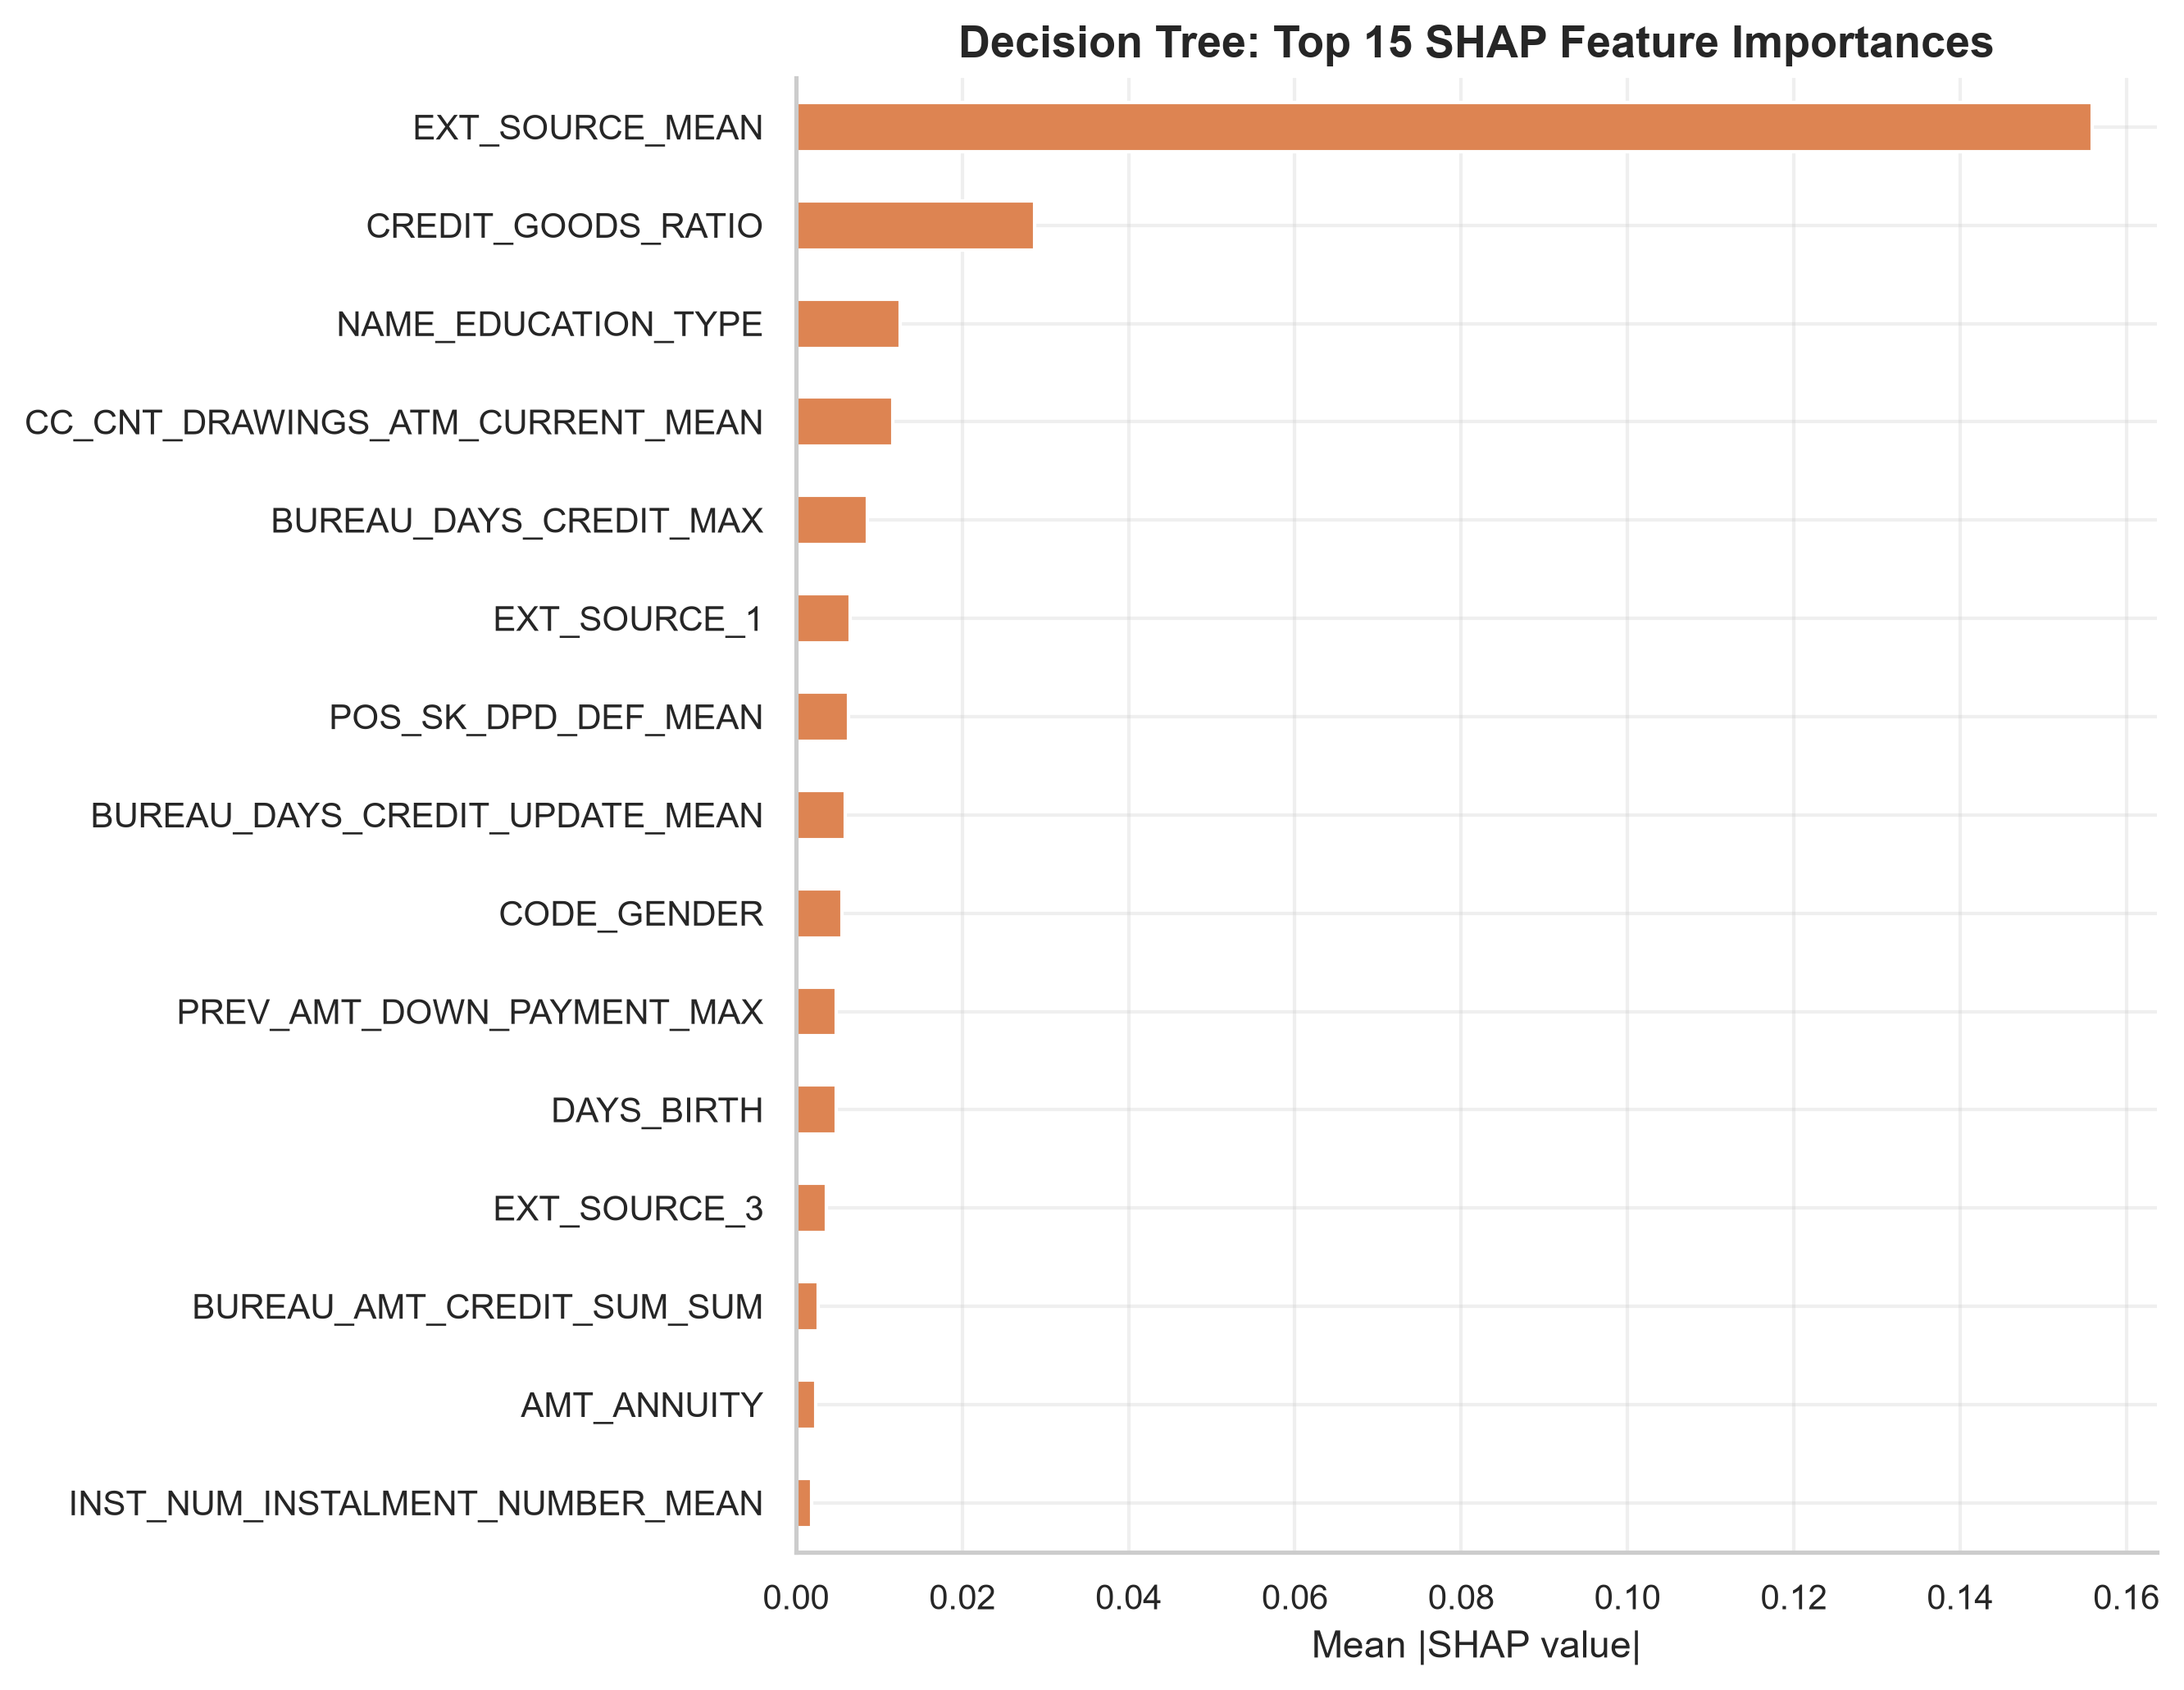

EXT_SOURCE_MEAN                     0.155886
CREDIT_GOODS_RATIO                  0.028685
NAME_EDUCATION_TYPE                 0.012541
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN    0.011638
BUREAU_DAYS_CREDIT_MAX              0.008560
EXT_SOURCE_1                        0.006483
POS_SK_DPD_DEF_MEAN                 0.006358
BUREAU_DAYS_CREDIT_UPDATE_MEAN      0.005893
CODE_GENDER                         0.005538
PREV_AMT_DOWN_PAYMENT_MAX           0.004868
DAYS_BIRTH                          0.004845
EXT_SOURCE_3                        0.003625
BUREAU_AMT_CREDIT_SUM_SUM           0.002622
AMT_ANNUITY                         0.002367
INST_NUM_INSTALMENT_NUMBER_MEAN     0.001854
dtype: float64

In [18]:
# ============================================================
# SHAP Explainability (Non-PCA Track, TreeExplainer): Summary & Importance
# ============================================================

import shap

DATA_DIR = Path("../data/processed")

X_train_full = pd.read_csv(DATA_DIR / "X_train_full.csv")
X_test_full = pd.read_csv(DATA_DIR / "X_test_full.csv")
y_train_full = pd.read_csv(DATA_DIR / "y_train_full.csv").squeeze()

tree_model_shap = DecisionTreeClassifier(random_state=RANDOM_STATE, **random_search.best_params_)
tree_model_shap.fit(X_train_full, y_train_full)

explainer = shap.TreeExplainer(tree_model_shap)

shap_sample = X_test_full.sample(2000, random_state=RANDOM_STATE)
shap_values_raw = explainer.shap_values(shap_sample)

# shap's return shape for binary classifiers varies by version: a list of two arrays
# [class_0, class_1], a single 2D array, or a 3D array (n_samples, n_features, n_classes).
# The block below normalizes all three cases to the "default" (positive) class.
if isinstance(shap_values_raw, list):
    shap_values_default = shap_values_raw[1]
elif np.ndim(shap_values_raw) == 3:
    shap_values_default = shap_values_raw[:, :, 1]
else:
    shap_values_default = shap_values_raw

shap.summary_plot(shap_values_default, shap_sample, show=False)
fig = plt.gcf()
plt.title("Decision Tree: SHAP Summary Plot")
plt.tight_layout()
pu.save_fig(fig, "07_tree_shap_summary")
plt.show()

mean_abs_shap = pd.Series(
    np.abs(shap_values_default).mean(axis=0), index=X_test_full.columns
).sort_values(ascending=False)

top_features = mean_abs_shap.head(15)

fig, ax = plt.subplots(figsize=(9, 7))
top_features.sort_values().plot(kind="barh", ax=ax, color="#DD8452")
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("Decision Tree: Top 15 SHAP Feature Importances")
plt.tight_layout()
pu.save_fig(fig, "07_tree_shap_feature_importance")
plt.show()

top_features.to_frame("Mean |SHAP value|").to_csv(Path("../results") / "07_tree_shap_top_features.csv")
top_features

Figure saved to: ..\figures\07_tree_shap_dependence.png


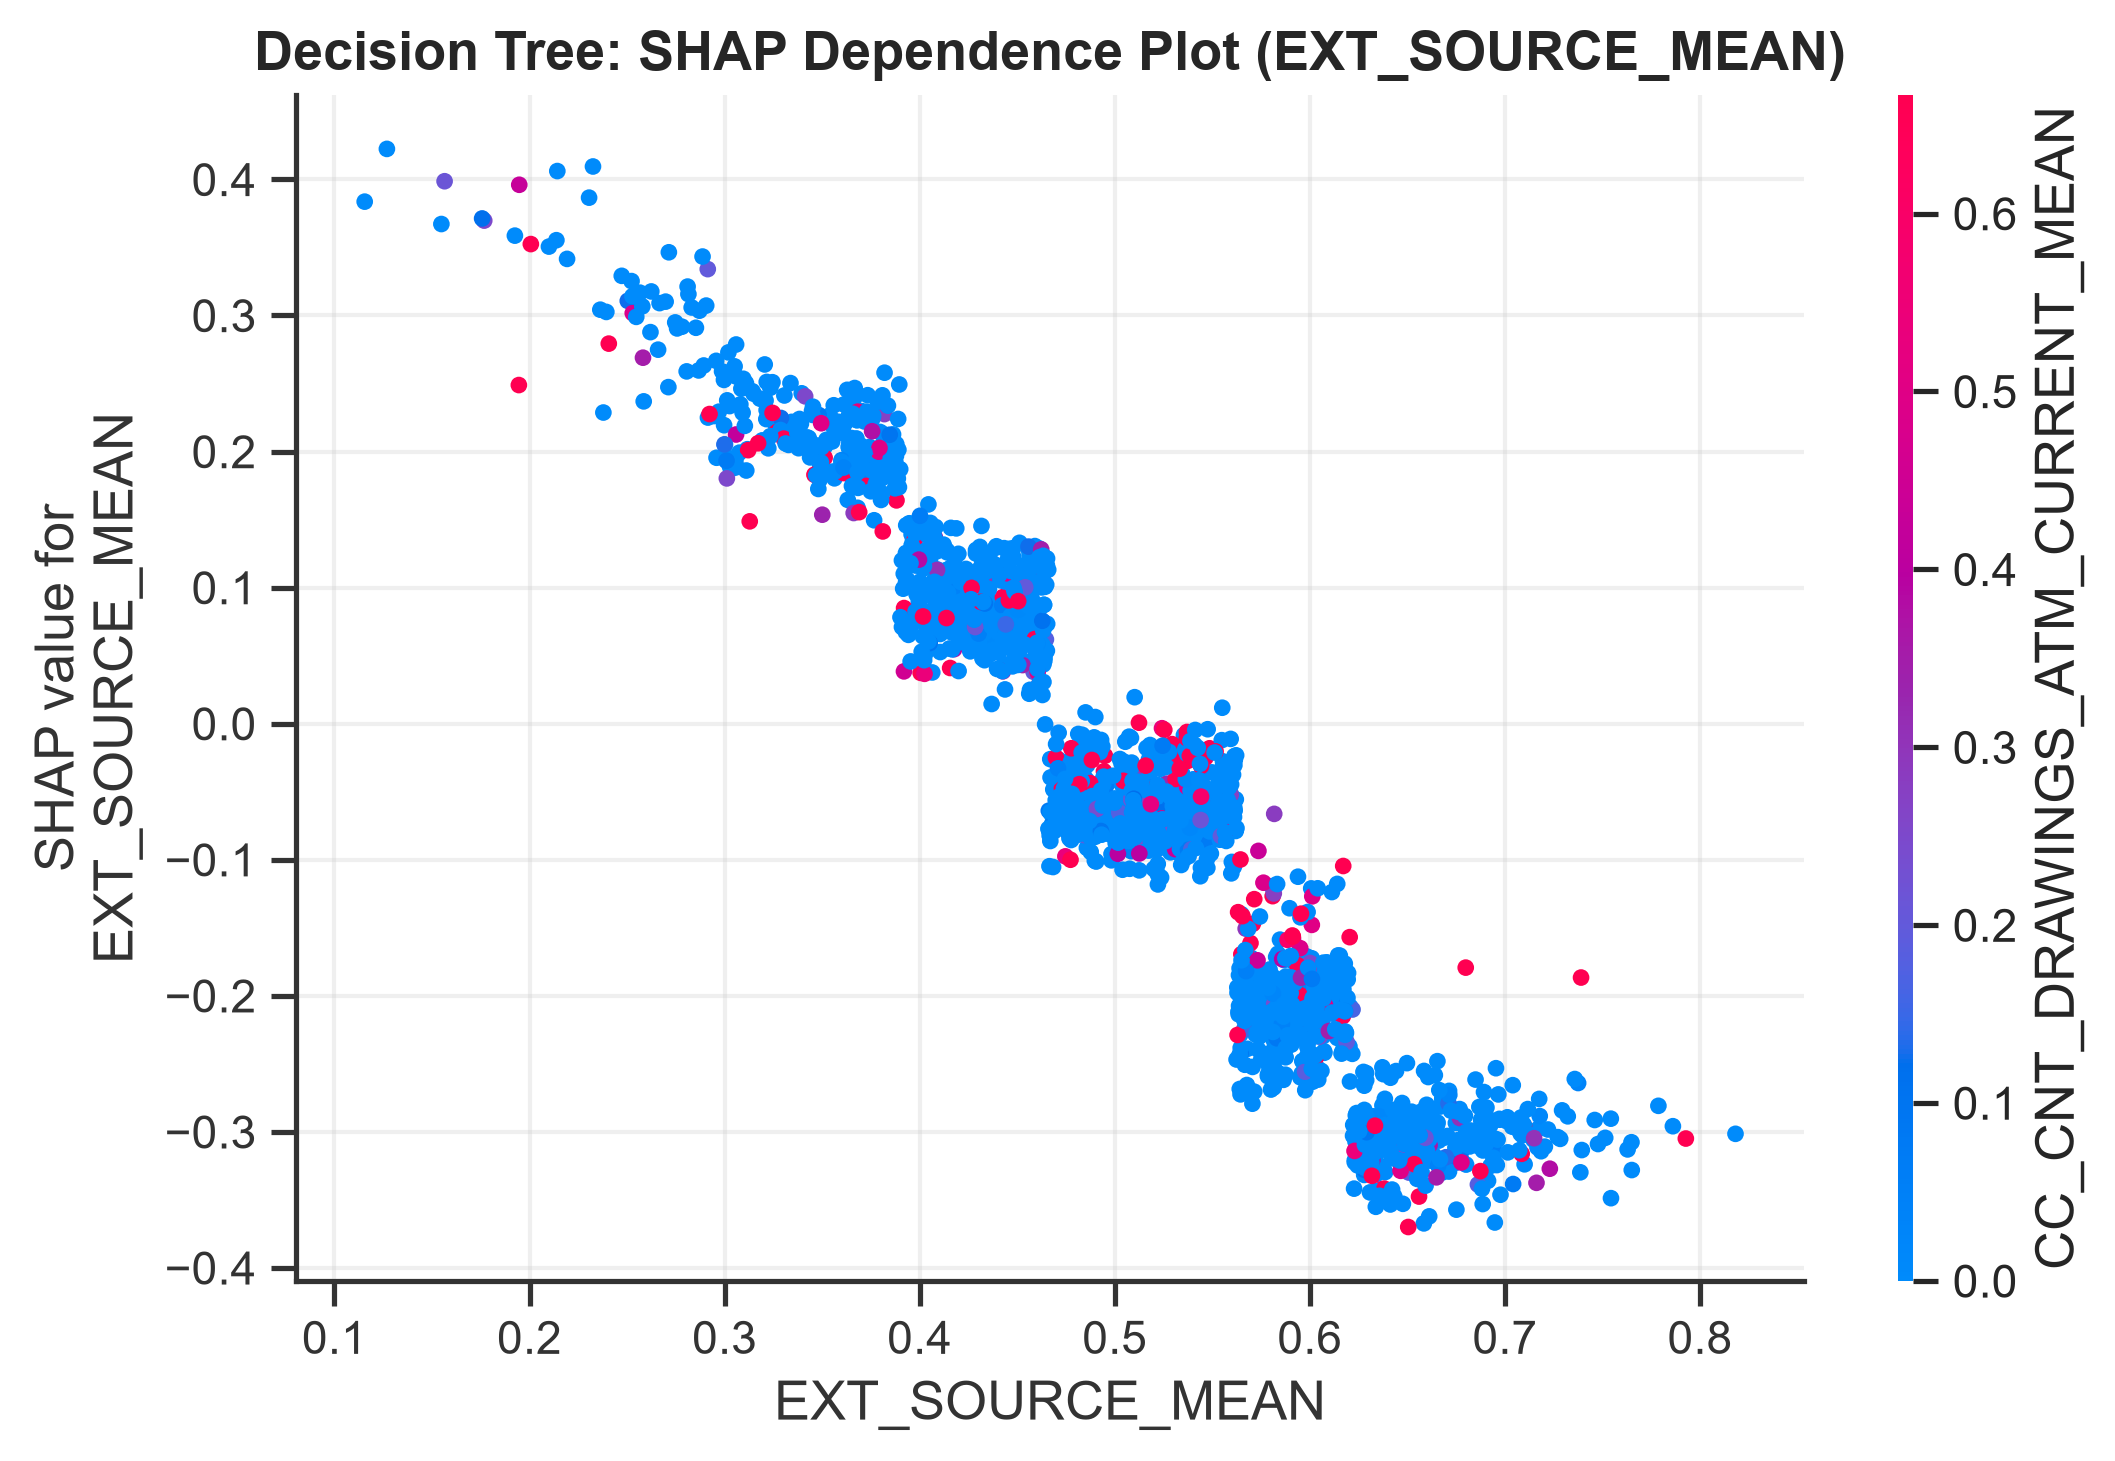

Low-risk applicant  - predicted default probability: 0.0566
High-risk applicant - predicted default probability: 0.8977


Figure saved to: ..\figures\07_tree_shap_local_low_risk.png


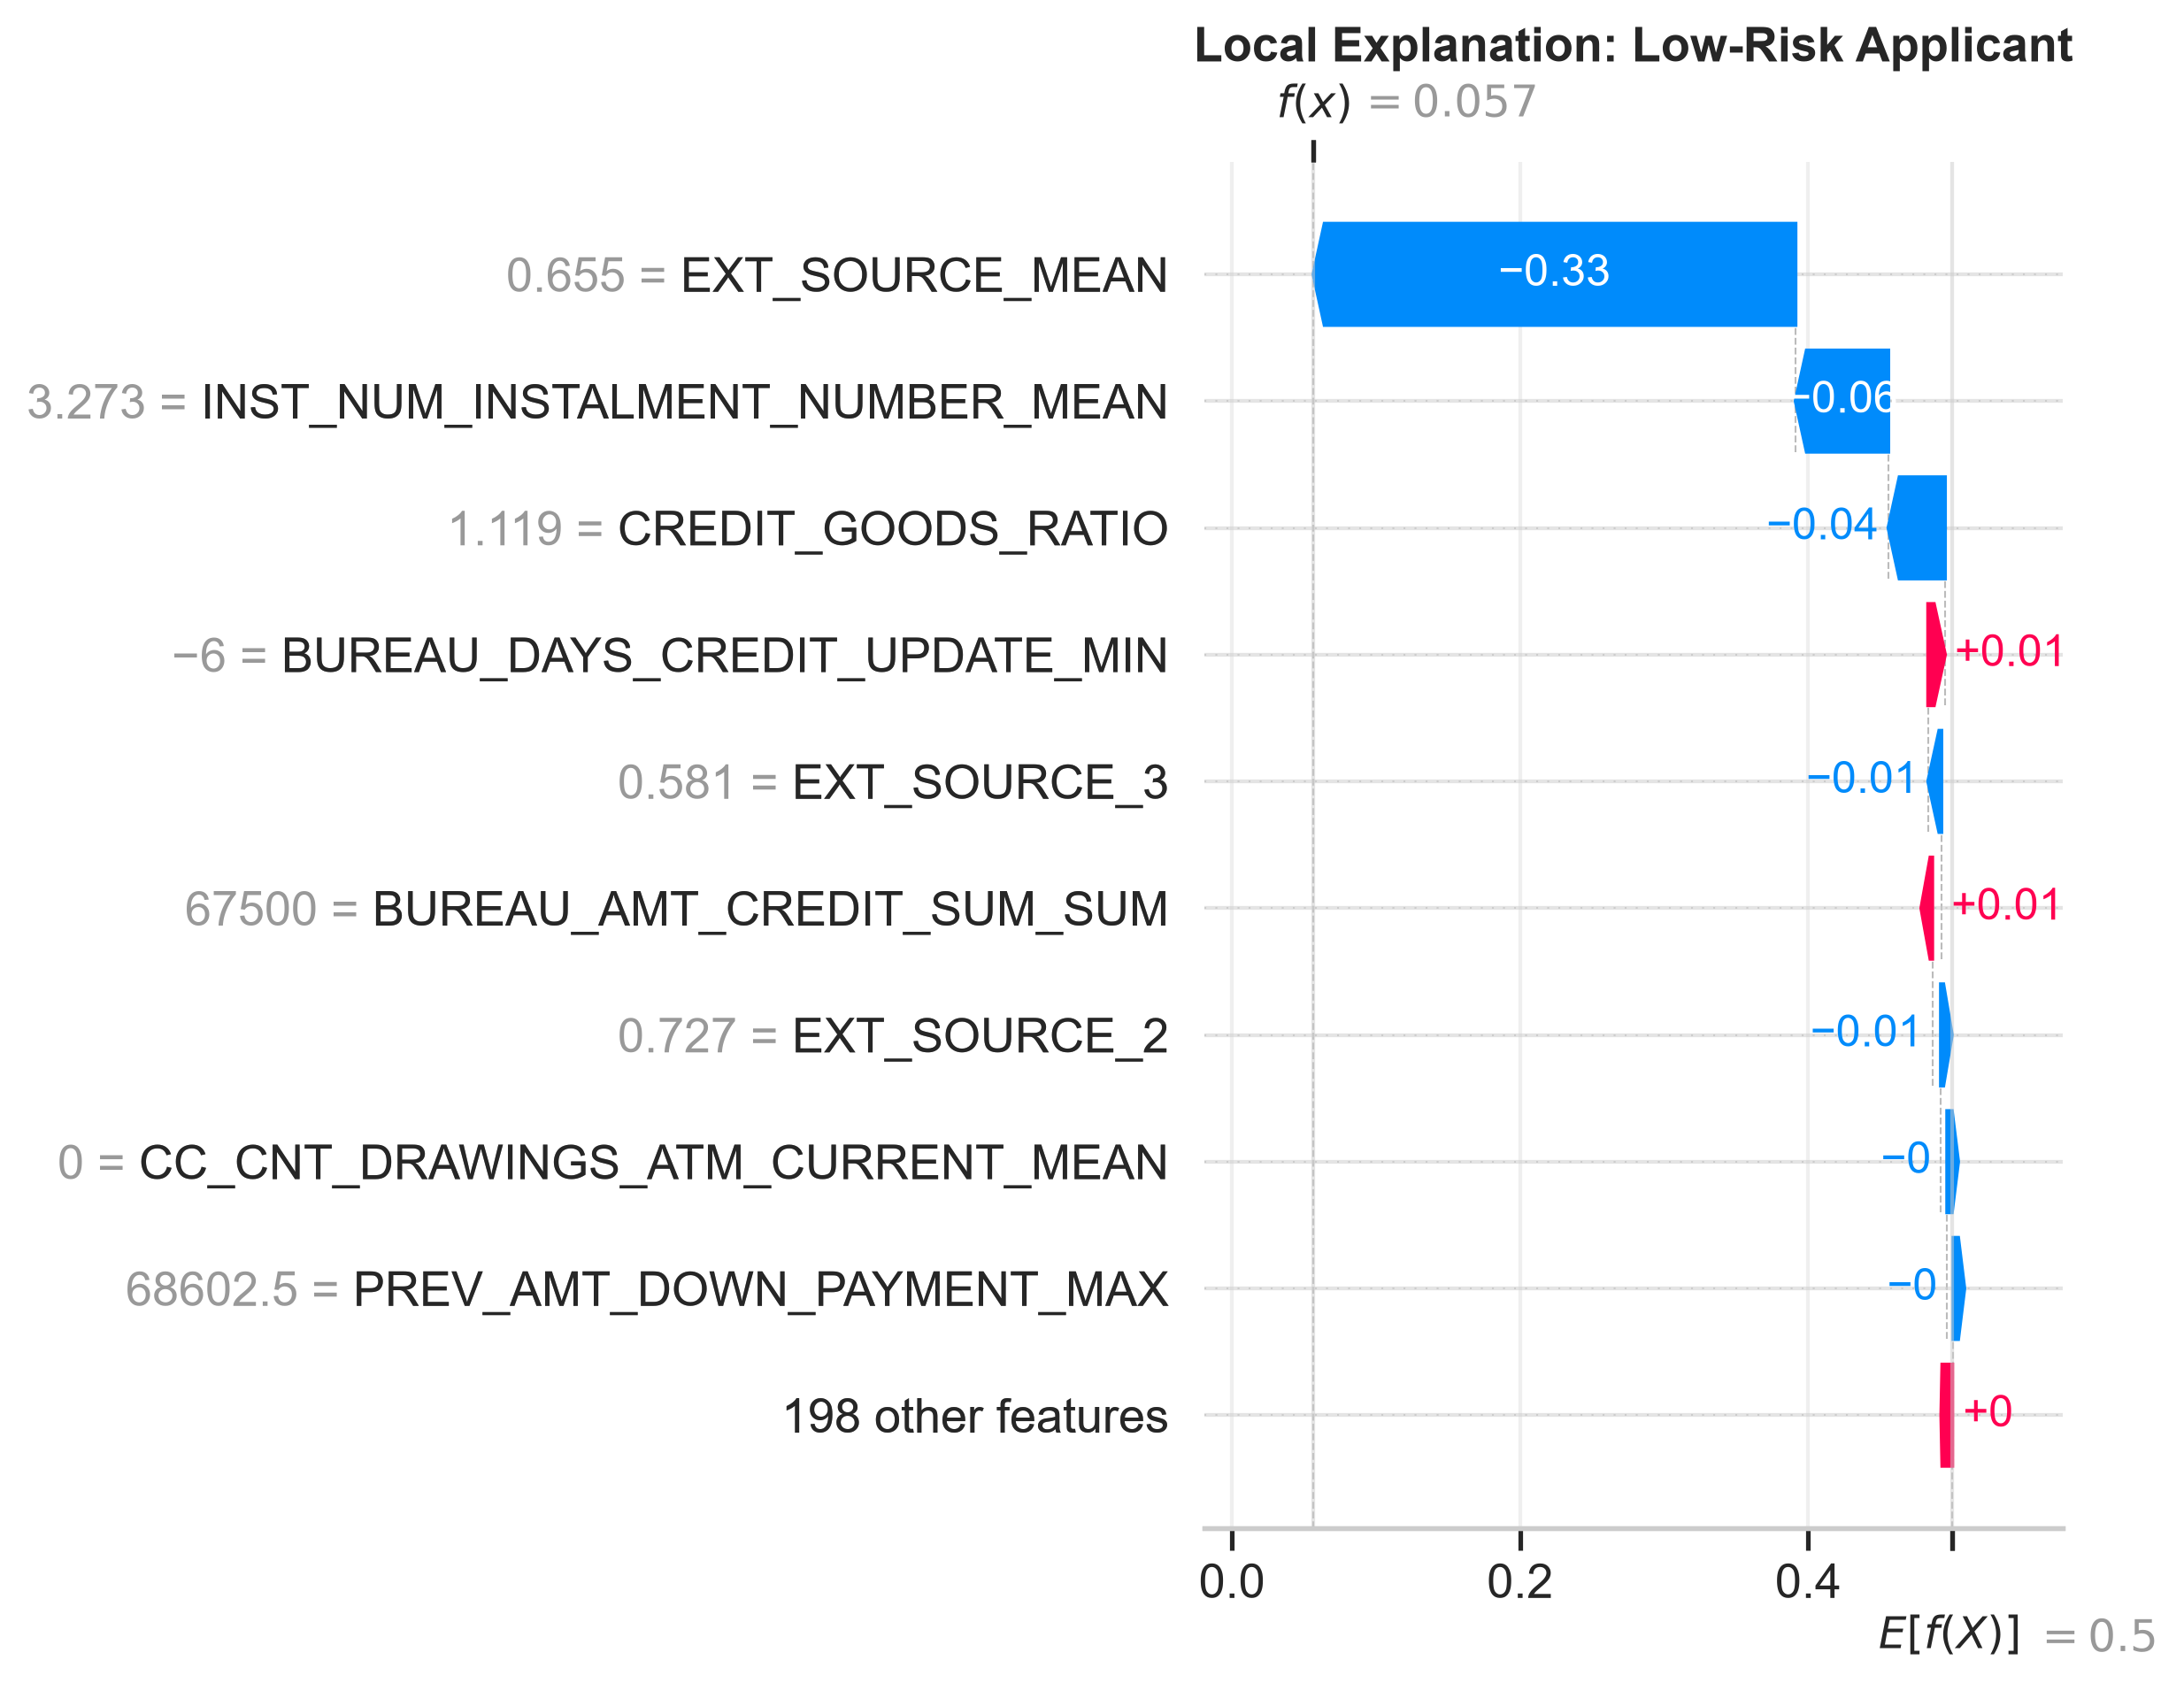

Figure saved to: ..\figures\07_tree_shap_local_high_risk.png


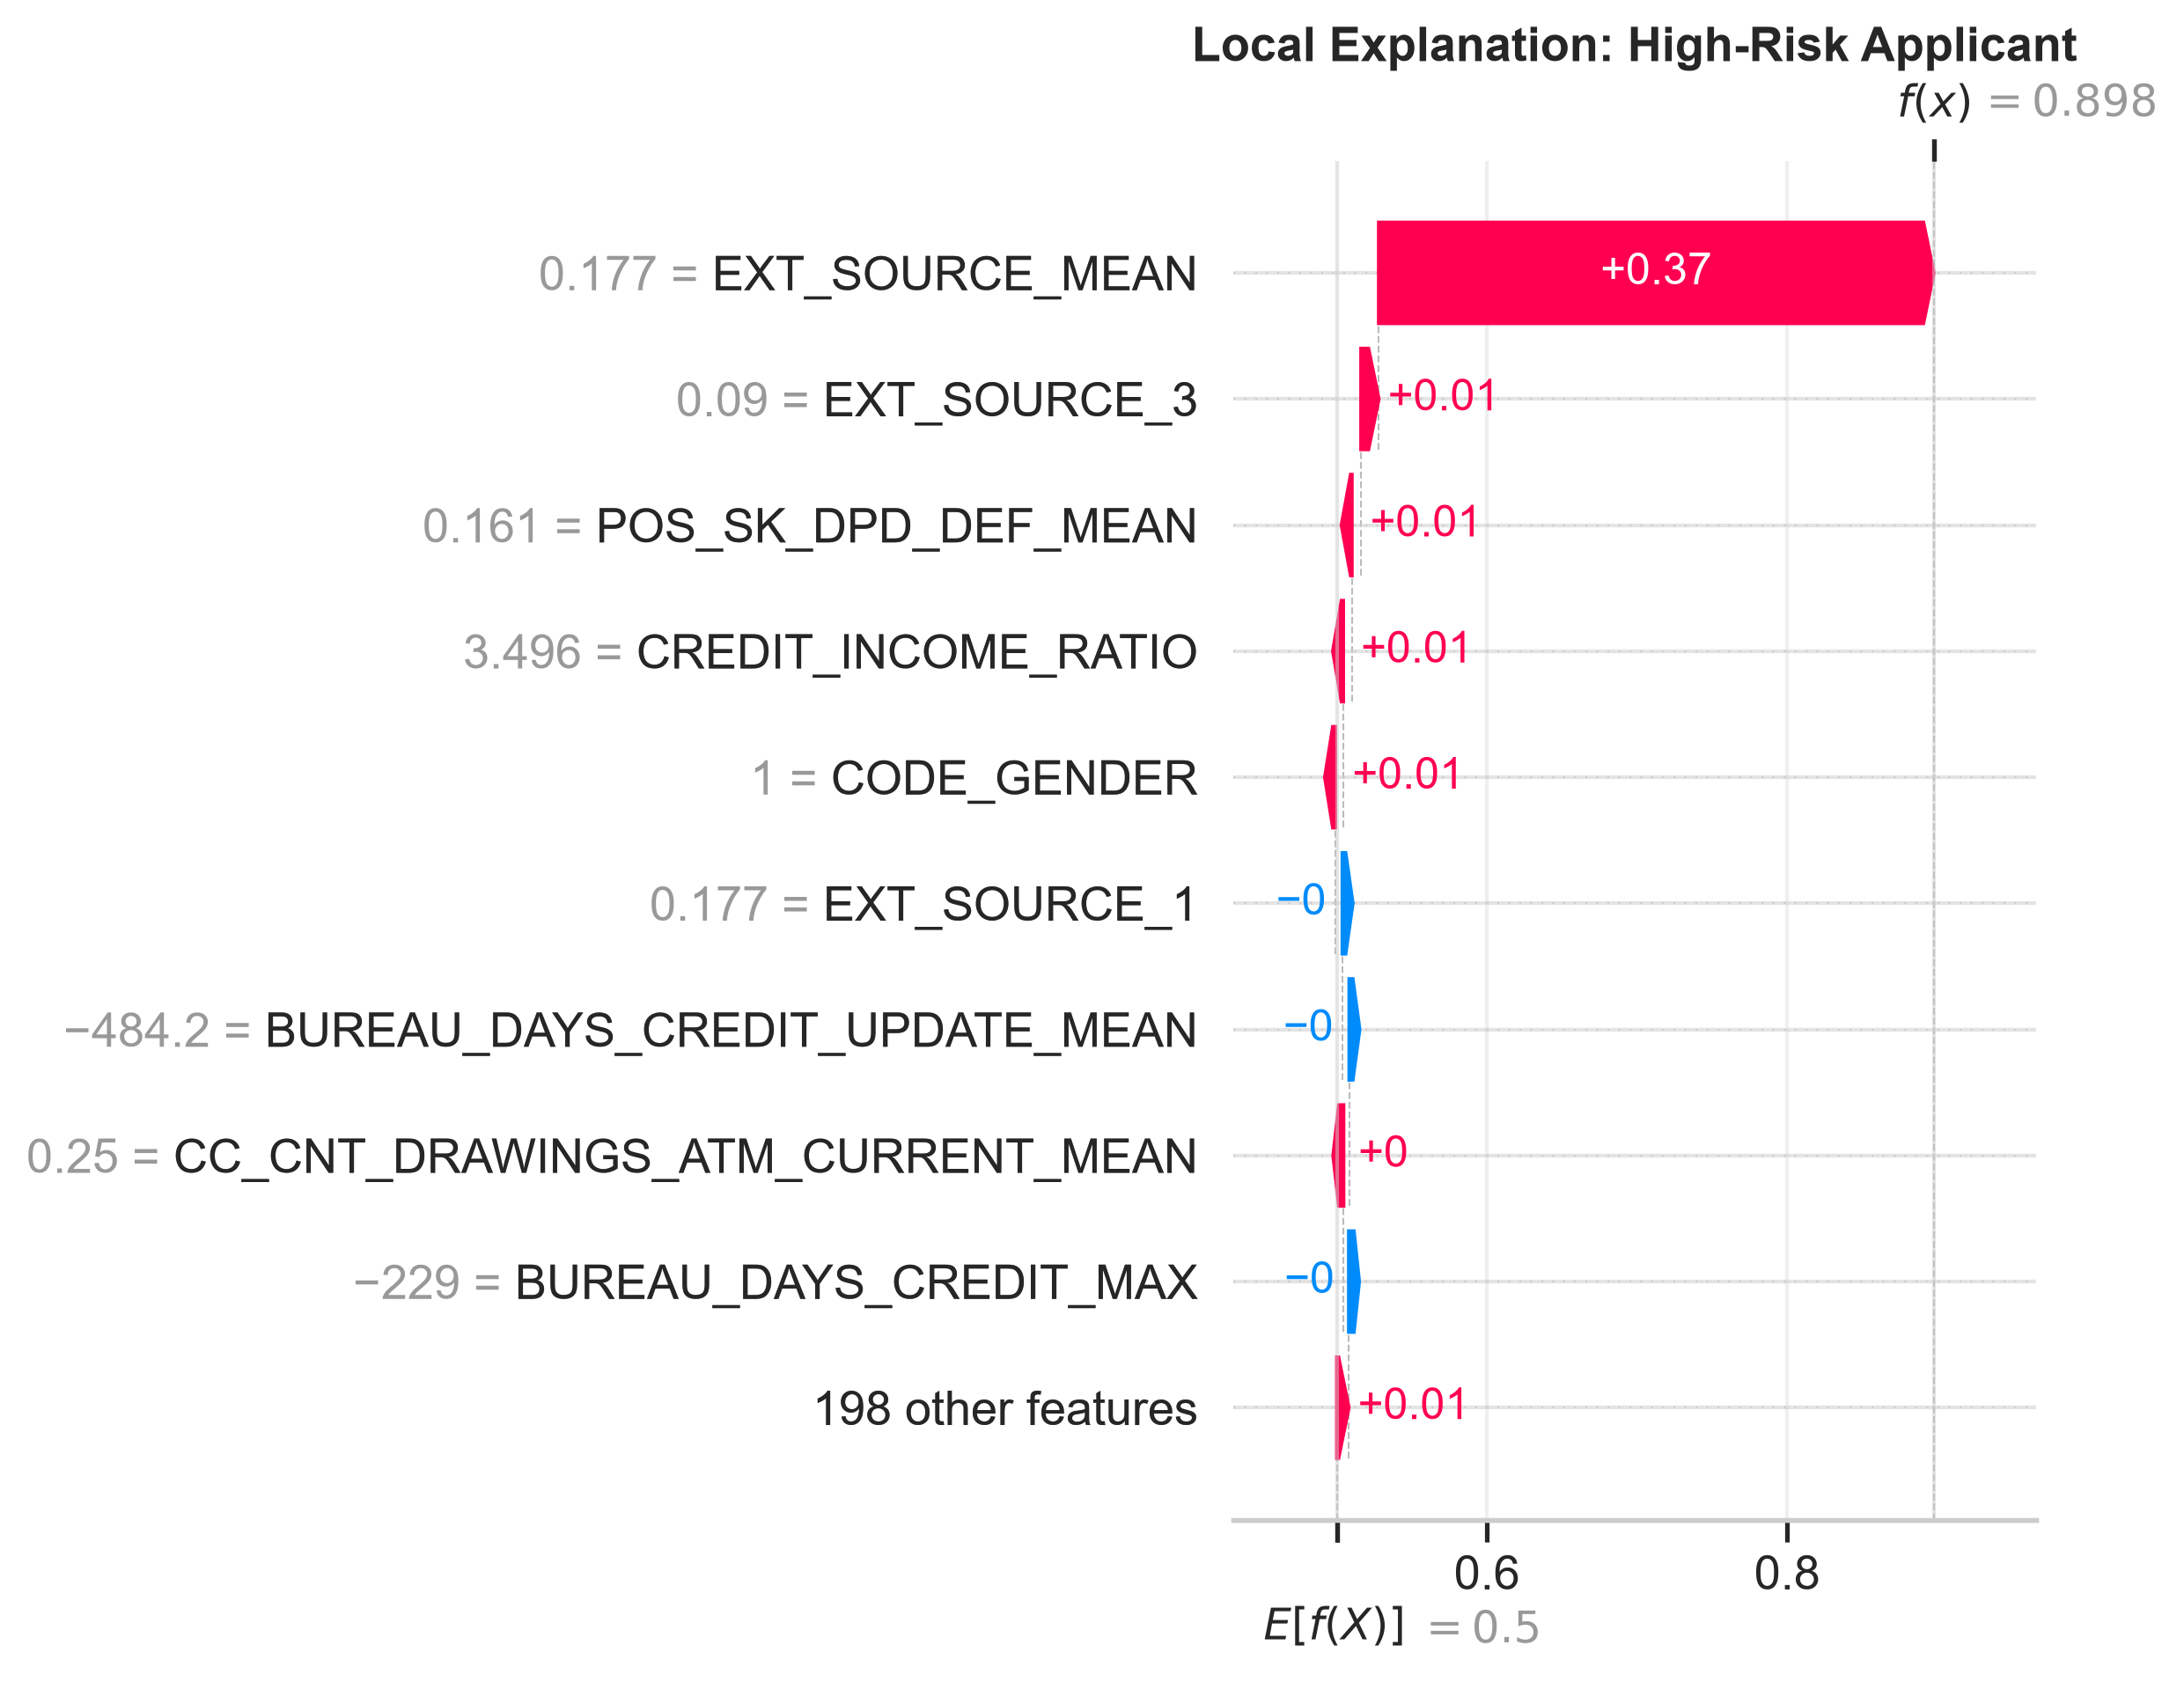

In [19]:
# ============================================================
# SHAP Dependence Plot & Local Explanations
# ============================================================

top_feature_name = mean_abs_shap.index[0]

shap.dependence_plot(top_feature_name, shap_values_default, shap_sample, show=False)
fig = plt.gcf()
plt.title(f"Decision Tree: SHAP Dependence Plot ({top_feature_name})")
plt.tight_layout()
pu.save_fig(fig, "07_tree_shap_dependence")
plt.show()

predicted_prob_shap_sample = tree_model_shap.predict_proba(shap_sample)[:, 1]
low_risk_idx = int(np.argmin(predicted_prob_shap_sample))
high_risk_idx = int(np.argmax(predicted_prob_shap_sample))

print(f"Low-risk applicant  - predicted default probability: {predicted_prob_shap_sample[low_risk_idx]:.4f}")
print(f"High-risk applicant - predicted default probability: {predicted_prob_shap_sample[high_risk_idx]:.4f}")

# Use the Explanation-object API for clean waterfall plots (handles multi-class base values internally)
explanation_full = explainer(shap_sample, check_additivity=False)
explanation = explanation_full[..., 1] if explanation_full.values.ndim == 3 else explanation_full

fig = plt.figure(figsize=(9, 6))
shap.plots.waterfall(explanation[low_risk_idx], show=False)
plt.title("Local Explanation: Low-Risk Applicant")
plt.tight_layout()
pu.save_fig(fig, "07_tree_shap_local_low_risk")
plt.show()

fig = plt.figure(figsize=(9, 6))
shap.plots.waterfall(explanation[high_risk_idx], show=False)
plt.title("Local Explanation: High-Risk Applicant")
plt.tight_layout()
pu.save_fig(fig, "07_tree_shap_local_high_risk")
plt.show()

### Business Interpretation: SHAP Explainability

Because a single decision tree makes hard, axis-aligned splits, its dependence plot
for the top feature often shows a step-function pattern rather than the smooth
relationship a linear or ensemble model would produce — this is a direct, visual
illustration of the tree's high-variance, threshold-based decision logic (e.g., "a
0.001 change in `EXT_SOURCE_MEAN` right at a learned split point can flip the entire
predicted outcome"), which is itself a data point for the paper's discussion of why
ensembling many trees (Random Forest/XGBoost/LightGBM) produces smoother, more
trustworthy risk gradients than any single tree. The local waterfall explanations
provide the same adverse-action / regulatory-disclosure value described in Notebook 06,
letting this notebook's cross-model SHAP comparison table (compiled in Notebook 15)
show whether a lender would reach the same "reasons for decision" regardless of which
underlying model architecture was deployed — a strong robustness argument if the top
2-3 SHAP features are consistent across models.